# 4. Clustering temático

Este notebook es el **cuarto paso del pipeline**, que tiene como objetivo descubrir la estructura temática latente del corpus (≈ 241k artículos) mediante reducción dimensional + clustering, y obtener una etiqueta temática para cada artículo.

**Pipeline:**
1. Carga de embeddings + datos textuales de los 6 medios
2. Reducción dimensional con UMAP (5D para clustering, 2D para visualización)
3. Búsqueda de hiperparámetros óptimos con Optuna (HDBSCAN + DBSCAN)
4. Modelado temático con BERTopic (reducción a 29 topics + reasignación de outliers)
5. Etiquetado manual de topics y macrotemas
6. Visualización de la distribución temática por medio

In [1]:
! pip install -q bertopic optuna


[notice] A new release of pip is available: 24.3.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


## 0. Configuración e imports

Se fija `random_state=42` en todos los algoritmos estocásticos (UMAP, Optuna) para garantizar reproducibilidad. La semilla no afecta a la calidad del resultado pero permite comparar ejecuciones.

In [2]:
import json
import warnings
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import umap
import optuna
import hdbscan
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
np.random.seed(42)

import pickle
from bertopic import BERTopic
from umap import UMAP as UMAP_bt
from hdbscan import HDBSCAN as HDBSCAN_bt
from sklearn.feature_extraction.text import CountVectorizer
import textwrap


In [ ]:
DATA_DIR   = Path('../data/processed')
EMB_DIR    = Path('../embeddings')
OUTPUT_DIR = Path('../output/clustering_6medios')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MEDIOS_META = {
    'elconfidencial': ('El Confidencial', '#4e79a7'),
    'eldiario':       ('elDiario.es',     '#59a14f'),
    'elmundo':        ('El Mundo',        '#f28e2b'),
    'elpais':         ('El País',         '#e15759'),
    'okdiario':       ('OKDiario',        '#b07aa1'),
    'publico':        ('Público',         '#76b7b2'),
}

MAPPING = {
    'El Confidencial': 'elconfidencial',
    'elDiario.es':     'eldiario',
    'El Mundo':        'elmundo',
    'El País':         'elpais',
    'OKDiario':        'okdiario',
    'Público':         'publico',
}

MEDIOS  = list(MEDIOS_META.keys())
COLORS  = {slug: meta[1] for slug, meta in MEDIOS_META.items()}
NOMBRES = {slug: meta[0] for slug, meta in MEDIOS_META.items()}

print('Configuración lista')
print(f'Medios: {MEDIOS}')
print(f'Output: {OUTPUT_DIR.resolve()}')

## 1. Carga de datos y embeddings

### Estrategia de carga de embeddings

Los 6 medios tienen situaciones distintas según cómo se generaron los embeddings originalmente:

| Medio | Situación | Acción |
|-------|-----------|--------|
| elconfidencial, eldiario, publico | El embedding completo (`_embeddings.npy`) incluye artículos descartados en el filtrado. Ya existe `_embeddings_filtrado.npy`. | Cargar directamente el fichero filtrado. |
| elmundo, elpais, okdiario | Los embeddings se generaron ya sobre el conjunto filtrado. `_embeddings.npy` tiene exactamente el mismo número de filas que el JSON filtrado. | Cargar `_embeddings.npy` y guardar como `_embeddings_filtrado.npy` para consistencia. |

En ambos casos, el resultado es una matriz donde la fila `i` corresponde al artículo `i` del DataFrame del medio.

In [3]:
MEDIOS_CON_FULL_EMB = {'elconfidencial', 'eldiario', 'publico'}

todas        = []
embeddings_list = []

for medio in MEDIOS:
    path_json        = DATA_DIR / f'{medio}_limpio_filtrado.json'
    noticias         = json.loads(path_json.read_text(encoding='utf-8'))
    emb_filtrado_path = EMB_DIR / f'{medio}_embeddings_filtrado.npy'

    if emb_filtrado_path.exists():
        emb_filtrado = np.load(emb_filtrado_path)
        print(f'[{medio}] filtrado cargado desde disco → {emb_filtrado.shape}')
    elif medio in MEDIOS_CON_FULL_EMB:
        indices      = [int(n['id'].split('_')[-1]) for n in noticias]
        emb_full     = np.load(EMB_DIR / f'{medio}_embeddings.npy')
        emb_filtrado = emb_full[indices]
        np.save(emb_filtrado_path, emb_filtrado)
        print(f'[{medio}] filtrado generado y guardado → {emb_filtrado.shape}')
    else:
        emb_filtrado = np.load(EMB_DIR / f'{medio}_embeddings.npy')
        assert len(emb_filtrado) == len(noticias), (
            f'{medio}: {len(emb_filtrado)} embeddings != {len(noticias)} artículos'
        )
        np.save(emb_filtrado_path, emb_filtrado)
        print(f'[{medio}] embeddings directos guardados como filtrado → {emb_filtrado.shape}')

    todas.extend(noticias)
    embeddings_list.append(emb_filtrado)

# Construir DataFrame unificado
df = pd.DataFrame(todas)
df['medio']    = df['medio'].map(MAPPING)
df['fecha_dt'] = pd.to_datetime(df['fecha'], errors='coerce', format='mixed')
df['año']      = df['fecha_dt'].dt.year
df['mes']      = df['fecha_dt'].dt.to_period('M')

embeddings = np.vstack(embeddings_list)

assert len(df) == len(embeddings), f'Desajuste: {len(df)} filas vs {len(embeddings)} embeddings'

print(f'\nTotal: {len(df):,} artículos | embeddings: {embeddings.shape}')
print(df.groupby('medio').size().rename('artículos').to_frame().to_string())

[elconfidencial] filtrado cargado desde disco → (36483, 1024)
[eldiario] filtrado cargado desde disco → (38463, 1024)
[elmundo] filtrado cargado desde disco → (22994, 1024)
[elpais] filtrado cargado desde disco → (64933, 1024)
[okdiario] filtrado cargado desde disco → (51973, 1024)
[publico] filtrado cargado desde disco → (26057, 1024)

Total: 240,903 artículos | embeddings: (240903, 1024)
                artículos
medio                    
elconfidencial      36483
eldiario            38463
elmundo             22994
elpais              64933
okdiario            51973
publico             26057


In [4]:
total_zeros = 0

for medio in MEDIOS:
    path_emb  = EMB_DIR  / f'{medio}_embeddings_filtrado.npy'
    path_json = DATA_DIR / f'{medio}_limpio_filtrado.json'

    if not path_emb.exists():
        print(f'[{medio}] sin _embeddings_filtrado.npy, saltando')
        continue

    emb     = np.load(path_emb)
    mask_ok = np.linalg.norm(emb, axis=1) > 1e-6
    n_zeros = (~mask_ok).sum()

    if n_zeros == 0:
        print(f'[{medio}] OK — sin zeros ({emb.shape[0]:,} artículos)')
        continue

    # Copia de seguridad del JSON (solo si no existe ya)
    path_backup = DATA_DIR / f'{medio}_limpio_filtrado_original.json'
    if not path_backup.exists():
        shutil.copy(path_json, path_backup)
        print(f'[{medio}] backup guardado → {path_backup.name}')

    # Sobreescribir .npy sin los zeros
    np.save(path_emb, emb[mask_ok])

    # Sobreescribir JSON sincronizado
    noticias = json.loads(path_json.read_text(encoding='utf-8'))
    noticias_clean = [n for n, ok in zip(noticias, mask_ok) if ok]
    path_json.write_text(
        json.dumps(noticias_clean, ensure_ascii=False, indent=2), encoding='utf-8'
    )

    print(f'[{medio}] eliminados {n_zeros} zeros → {mask_ok.sum():,} artículos')
    total_zeros += n_zeros

if total_zeros > 0:
    for cache in ['umap_5d.npy', 'umap_2d.npy', 'outlier_labels.npy', 'optuna_studies.pkl']:
        p = OUTPUT_DIR / cache
        if p.exists():
            p.unlink()
            print(f'caché eliminado: {cache}')
    print(f'\nTotal zeros eliminados: {total_zeros} → vuelve a ejecutar la celda de carga')

[elconfidencial] OK — sin zeros (36,483 artículos)
[eldiario] OK — sin zeros (38,463 artículos)
[elmundo] OK — sin zeros (22,994 artículos)
[elpais] OK — sin zeros (64,933 artículos)
[okdiario] OK — sin zeros (51,973 artículos)
[publico] OK — sin zeros (26,057 artículos)


In [5]:
print('=== Artículos eliminados por embeddings cero ===')
total_eliminados = 0
for medio in MEDIOS:
    path_orig  = DATA_DIR / f'{medio}_limpio_filtrado_original.json'
    path_clean = DATA_DIR / f'{medio}_limpio_filtrado.json'

    if not path_orig.exists():
        print(f'[{medio}] sin backup — no se eliminó nada')
        continue

    n_orig  = len(json.loads(path_orig.read_text(encoding='utf-8')))
    n_clean = len(json.loads(path_clean.read_text(encoding='utf-8')))
    eliminados = n_orig - n_clean
    total_eliminados += eliminados
    print(f'[{medio}] {n_orig:,} → {n_clean:,}  (eliminados: {eliminados})')

print(f'\nTotal eliminados: {total_eliminados}')

=== Artículos eliminados por embeddings cero ===
[elconfidencial] 36,718 → 36,483  (eliminados: 235)
[eldiario] 38,494 → 38,463  (eliminados: 31)
[elmundo] 23,012 → 22,994  (eliminados: 18)
[elpais] 64,936 → 64,933  (eliminados: 3)
[okdiario] 52,023 → 51,973  (eliminados: 50)
[publico] sin backup — no se eliminó nada

Total eliminados: 337


### Limpieza de embeddings cero

Durante la generación de embeddings (notebook `3_embedings.ipynb`), algunos artículos fallaron por OOM u otros errores y se guardaron como vectores de ceros en lugar de embeddings reales. Estos artículos pasaron el filtrado del EDA (tenían texto válido) pero su embedding es inútil para clustering.

**Qué hace esta celda:**
1. Detecta artículos con embedding cero (`norma < 1e-6`) en cada `_embeddings_filtrado.npy`
2. Guarda una copia de seguridad del JSON original como `_limpio_filtrado_original.json` (solo la primera vez)
3. Sobreescribe el `.npy` y el `.json` eliminando esos artículos, manteniéndolos sincronizados
4. Borra los cachés de UMAP y outliers para que se recomputen con los datos limpios

**A partir de la segunda ejecución** todos los medios salen `OK — sin zeros` y no se modifica nada. Para consultar cuántos se eliminaron, ver la celda siguiente.

## 2. EDA básico del corpus

Antes de reducir dimensiones es importante entender el corpus, que se hizo en el notebook 2_eda. No obstante, se incluye aquí un pequeño recordatorio de cómo son los datos, ya que un corpus muy desbalanceado (e.g., un medio con 10× más artículos que otro) puede sesgar los clusters hacia los temas del medio dominante. Lo tendremos en cuenta al interpretar los resultados.

=== Resumen del corpus ===
                artículos               fecha_min           fecha_max  sin_fecha           nombre
medio                                                                                            
elpais              64933 2023-03-25 04:00:01.076 2026-04-07 05:30:01          0          El País
okdiario            51973 2023-03-19 21:03:56.000 2026-04-09 21:58:31          6         OKDiario
eldiario            38463 2023-03-14 12:46:06.000 2026-03-18 06:01:47          0      elDiario.es
elconfidencial      36483 2023-03-15 00:00:00.000 2026-03-25 05:00:00          0  El Confidencial
publico             26057 2023-03-28 08:52:00.000 2026-03-25 21:35:00          0          Público
elmundo             22994 2023-03-27 22:03:01.000 2026-04-03 22:12:15          0         El Mundo


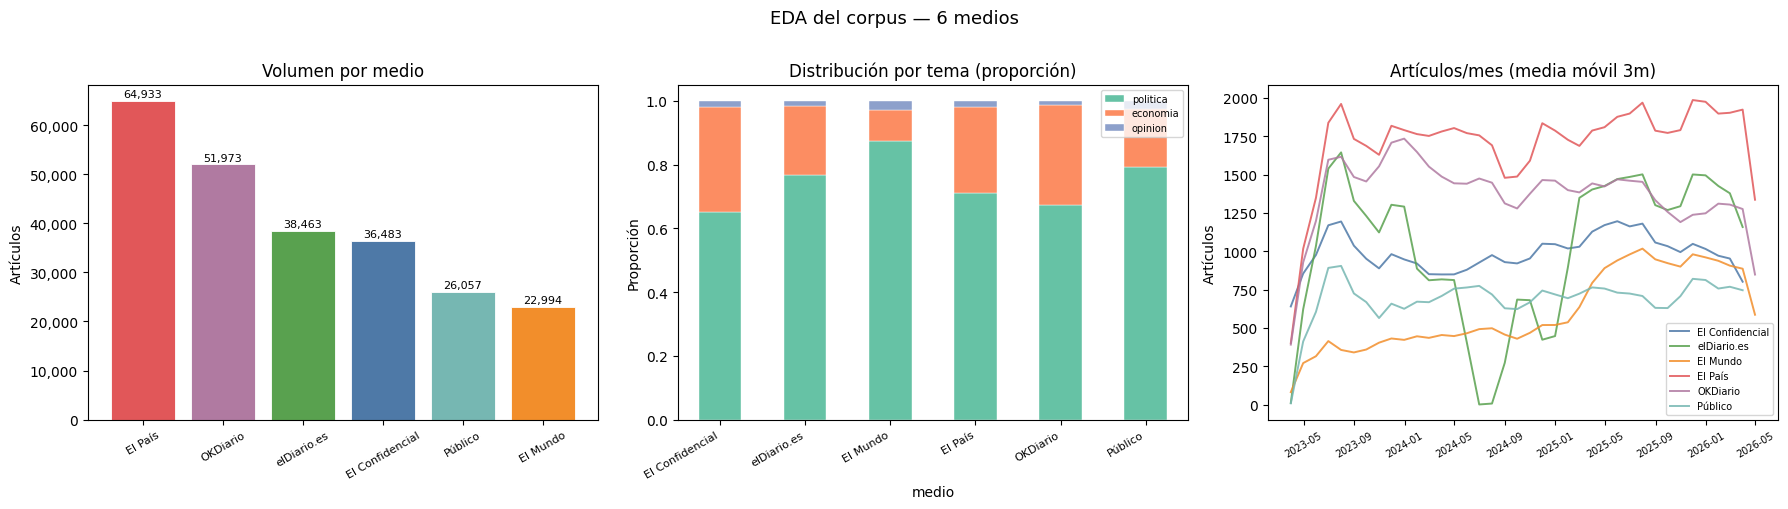

Figura guardada.


In [6]:
print('=== Resumen del corpus ===')
resumen = df.groupby('medio').agg(
    artículos=('id', 'count'),
    fecha_min=('fecha_dt', 'min'),
    fecha_max=('fecha_dt', 'max'),
    sin_fecha=('fecha_dt', lambda x: x.isna().sum()),
).sort_values('artículos', ascending=False)
resumen['nombre'] = resumen.index.map(NOMBRES)
print(resumen.to_string())


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ax = axes[0]
counts = df.groupby('medio').size().sort_values(ascending=False)
bars = ax.bar(
    [NOMBRES[m] for m in counts.index],
    counts.values,
    color=[COLORS[m] for m in counts.index],
    edgecolor='white', linewidth=0.6
)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f'{val:,}', ha='center', va='bottom', fontsize=8)
ax.set_title('Volumen por medio')
ax.set_ylabel('Artículos')
ax.tick_params(axis='x', rotation=30, labelsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))

ax = axes[1]
tabla_tema = pd.crosstab(df['medio'], df['tema'])
tabla_tema_n = tabla_tema.div(tabla_tema.sum(axis=1), axis=0)
temas_ord = tabla_tema_n.mean().sort_values(ascending=False).index.tolist()
tabla_tema_n[temas_ord].plot(
    kind='bar', ax=ax, stacked=True,
    color=sns.color_palette('Set2', len(temas_ord)),
    edgecolor='white', linewidth=0.3, legend=True
)
ax.set_title('Distribución por tema (proporción)')
ax.set_ylabel('Proporción')
ax.set_xticklabels([NOMBRES[m] for m in tabla_tema_n.index], rotation=30, ha='right', fontsize=8)
ax.legend(fontsize=7, loc='upper right')

ax = axes[2]
df_fecha = df.dropna(subset=['fecha_dt'])
df_fecha = df_fecha[df_fecha['fecha_dt'].dt.year >= 2020]
for medio in MEDIOS:
    serie = (df_fecha[df_fecha['medio'] == medio]
             .resample('ME', on='fecha_dt')['id']
             .count()
             .rolling(3, min_periods=1).mean())
    ax.plot(serie.index, serie.values, color=COLORS[medio],
            label=NOMBRES[medio], linewidth=1.4, alpha=0.85)
ax.set_title('Artículos/mes (media móvil 3m)')
ax.set_ylabel('Artículos')
ax.legend(fontsize=7)
ax.tick_params(axis='x', rotation=30, labelsize=7)

plt.suptitle('EDA del corpus — 6 medios', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_corpus.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura guardada.')

## 3. Reducción dimensional con UMAP

Los embeddings tienen 1024 dimensiones (modelo de tipo `bge-m3` o similar). Para clustering basado en densidad necesitamos reducir la dimensionalidad porque:
1. **Maldición de la dimensionalidad**: en espacios de alta dimensión las distancias euclídeas se homogeneízan y los algoritmos de densidad pierden poder discriminativo.
2. **Coste computacional**: HDBSCAN/DBSCAN escalan cuadráticamente con la dimensión.

### Dos proyecciones de UMAP

| Parámetros | Propósito | Configuración |
|-----------|-----------|---------------|
| 5D, `min_dist=0.0` | Clustering (compacta clusters, maximiza separación) | Entrada a HDBSCAN/DBSCAN |
| 2D, `min_dist=0.1` | Visualización (preserva estructura global) | Scatter plots |

`n_neighbors=30` es un buen compromiso entre estructura local (valores bajos) y global (valores altos) para corpora de >100k documentos. `metric='cosine'` es apropiado para embeddings de texto porque normaliza la magnitud del vector y solo mide la orientación semántica.

> **Nota sobre tiempo de cómputo:** UMAP sobre ~300k puntos tarda varios minutos. Se usa `low_memory=True` para evitar consumo excesivo de RAM.

In [7]:
UMAP_5D_PATH = OUTPUT_DIR / 'umap_5d.npy'
UMAP_2D_PATH = OUTPUT_DIR / 'umap_2d.npy'

if UMAP_5D_PATH.exists() and UMAP_2D_PATH.exists():
    umap_5d = np.load(UMAP_5D_PATH)
    umap_2d = np.load(UMAP_2D_PATH)
    print(f'UMAP cargado desde disco: 5D={umap_5d.shape}, 2D={umap_2d.shape}')
else:
    print('Calculando UMAP 5D (para clustering)...')
    reducer_5d = umap.UMAP(
        n_components=5,
        n_neighbors=30,
        min_dist=0.0,
        metric='cosine',
        random_state=42,
        low_memory=True,
    )
    umap_5d = reducer_5d.fit_transform(embeddings)
    np.save(UMAP_5D_PATH, umap_5d)
    print(f'UMAP 5D listo → {umap_5d.shape}')

    print('Calculando UMAP 2D (para visualización)...')
    reducer_2d = umap.UMAP(
        n_components=2,
        n_neighbors=30,
        min_dist=0.1,
        metric='cosine',
        random_state=42,
        low_memory=True,
    )
    umap_2d = reducer_2d.fit_transform(embeddings)
    np.save(UMAP_2D_PATH, umap_2d)
    print(f'UMAP 2D listo → {umap_2d.shape}')

df['umap_x'] = umap_2d[:, 0]
df['umap_y'] = umap_2d[:, 1]
print('Coordenadas 2D añadidas al DataFrame')

UMAP cargado desde disco: 5D=(240903, 5), 2D=(240903, 2)
Coordenadas 2D añadidas al DataFrame


## 4. Preparación para clustering

No se aplica eliminación de outliers en esta fase.
Los artículos cortos y errores de scraping ya fueron eliminados en el notebook `1_limpieza.ipynb`.
Todos los artículos del corpus pasan a BERTopic para maximizar la cobertura temática,
objetivo clave para el posterior reranking.


In [8]:
# Todos los artículos pasan a BERTopic — sin eliminación por outliers.
# El filtrado de textos cortos y basura de scraping ya se hizo en el notebook 1_limpieza.
df['outlier'] = 1

mask_clean    = pd.Series([True] * len(df), index=df.index)
umap_5d_clean = umap_5d
emb_clean     = embeddings

print(f'Total artículos para clustering: {len(df):,}')
print('Sin eliminación de outliers — todos los artículos pasan a BERTopic.')


Total artículos para clustering: 240,903
Sin eliminación de outliers — todos los artículos pasan a BERTopic.


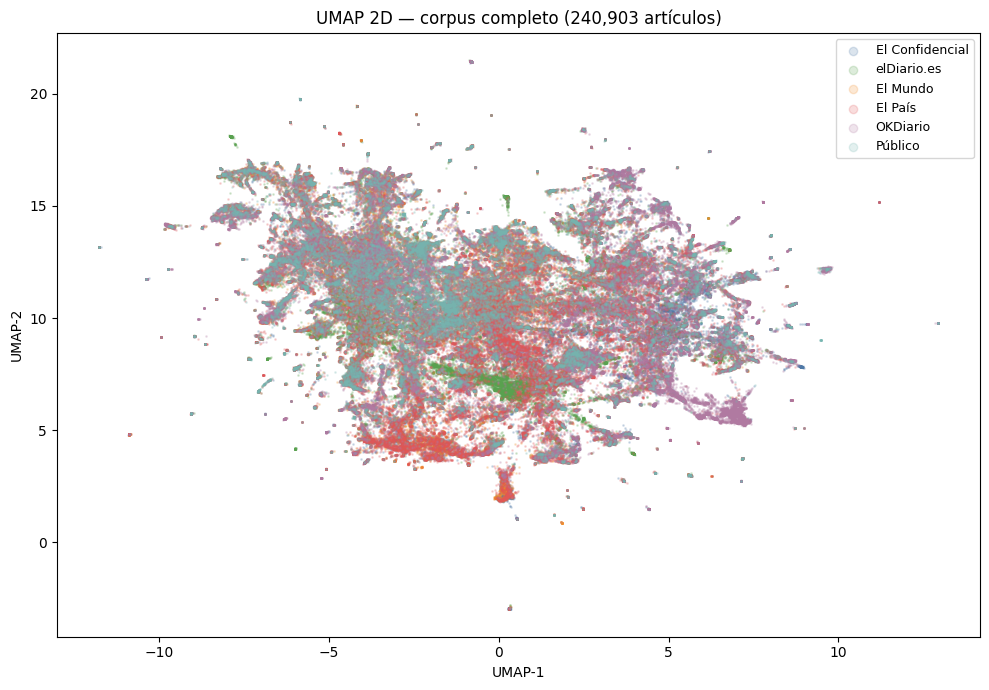

Total artículos: 240,903 — todos incluidos en el análisis


In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
for medio in MEDIOS:
    m = df['medio'] == medio
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1, alpha=0.2, color=COLORS[medio], label=NOMBRES[medio], rasterized=True)
ax.set_title(f'UMAP 2D — corpus completo ({len(df):,} artículos)', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(markerscale=6, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'corpus_completo_umap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Total artículos: {len(df):,} — todos incluidos en el análisis')


### Visualización UMAP — por tema y por medio

La visualización 2D permite validar cualitativamente que UMAP ha capturado estructura semántica. Se espera que artículos de temas similares aparezcan agrupados, independientemente del medio de origen.

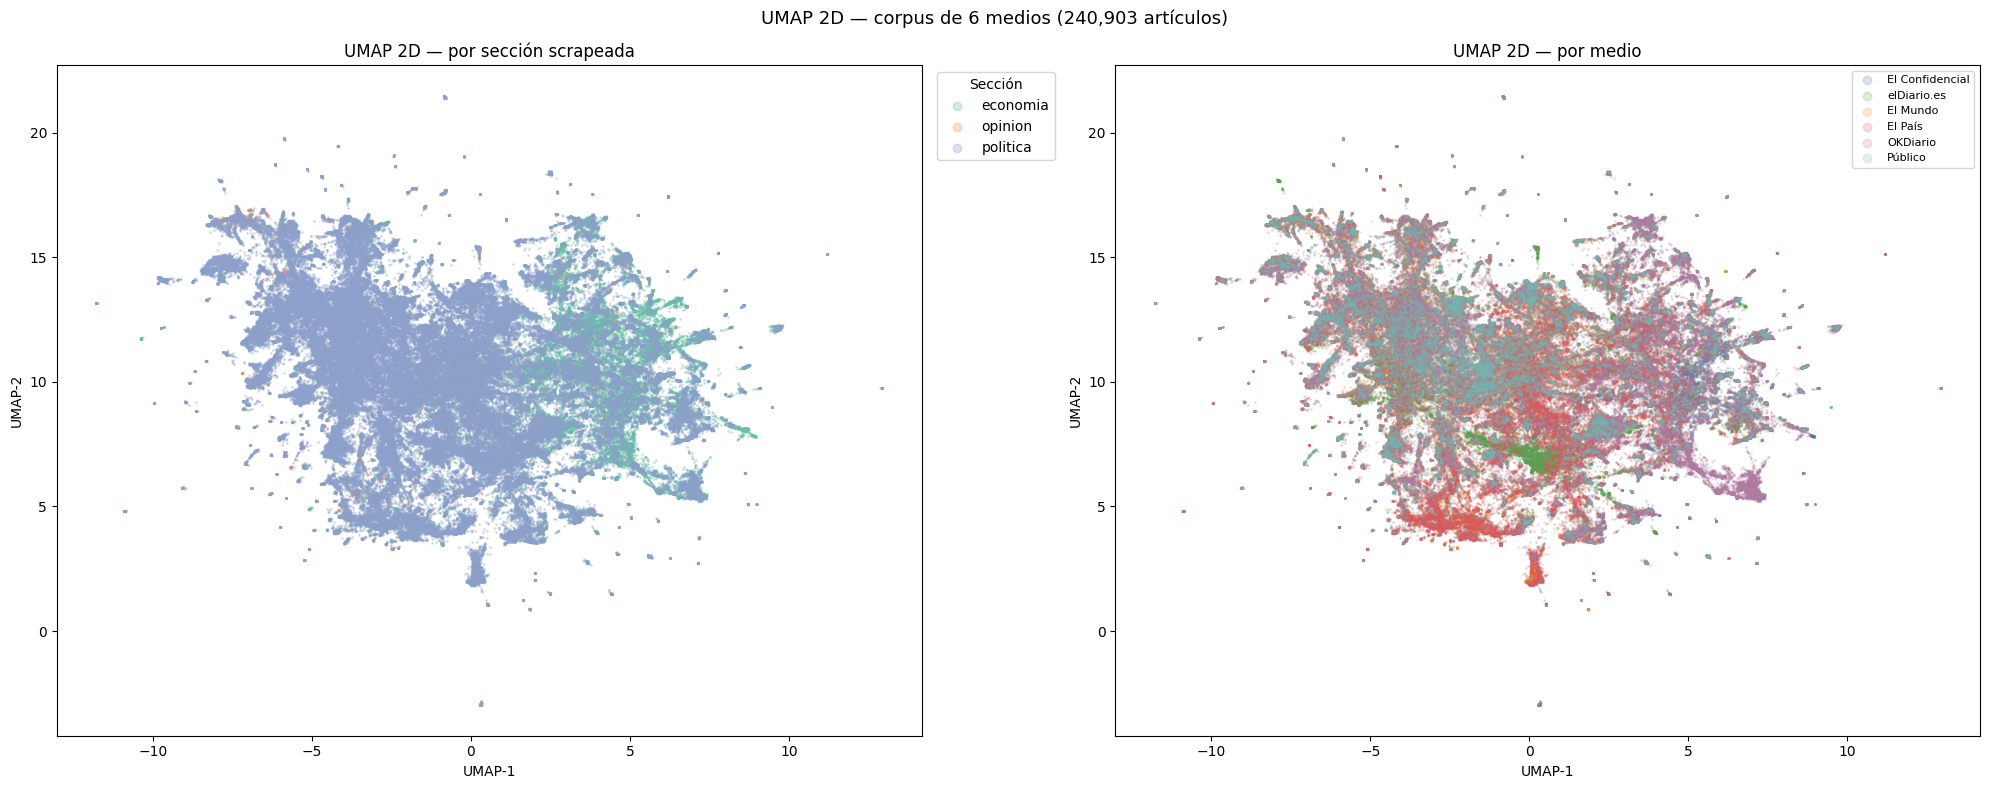

In [10]:
temas   = sorted(df['tema'].dropna().unique().tolist())
pal_tema = dict(zip(temas, sns.color_palette('Set2', len(temas))))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

ax = axes[0]
for tema, col in pal_tema.items():
    m = df['tema'] == tema
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1, alpha=0.3, color=col, label=tema, rasterized=True)
ax.set_title('UMAP 2D — por sección scrapeada', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(markerscale=6, title='Sección', bbox_to_anchor=(1.01, 1), loc='upper left')

ax = axes[1]
for medio in MEDIOS:
    m = df['medio'] == medio
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1, alpha=0.2, color=COLORS[medio], label=NOMBRES[medio], rasterized=True)
ax.set_title('UMAP 2D — por medio', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(markerscale=6, fontsize=8)

plt.suptitle(f'UMAP 2D — corpus de 6 medios ({len(df):,} artículos)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'umap_por_tema_medio.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Clustering — DBSCAN y HDBSCAN con Optuna

### ¿Por qué dos algoritmos?

| Algoritmo | Ventaja | Limitación |
|-----------|---------|------------|
| **HDBSCAN** | Detecta clusters de densidad variable, robusto a ruido, no necesita especificar K | Muy sensible a `min_cluster_size`; en corpus de noticias tiende a crear muchos micro-clusters por evento |
| **DBSCAN** | Más estable, un solo umbral de densidad, funciona bien si la densidad es relativamente uniforme | Requiere que todos los clusters tengan densidad similar; asigna mucho ruido si no |

### ¿Por qué Optuna?

La calidad del clustering depende críticamente de los hiperparámetros (`eps`, `min_samples`, `min_cluster_size`). Una búsqueda aleatoria o grid search es ineficiente; Optuna usa **TPE (Tree-structured Parzen Estimator)** que aprende qué regiones del espacio de búsqueda son prometedoras y las explora preferentemente.

### Función objetivo

Se maximiza el **coeficiente de silhouette** calculado sobre una muestra de 5.000 puntos no-ruido, con restricciones:
- `3 ≤ n_clusters ≤ 80`: evita soluciones triviales (1 cluster = todo igual) o sobreajustadas (>80 micro-clusters).
- `pct_ruido ≤ 0.4`: no más del 40% de artículos sin asignar (indicaría parámetros demasiado restrictivos).

El silhouette mide la cohesión interna vs. separación entre clusters. Va de -1 (mala) a +1 (perfecta).

In [11]:
OPTUNA_CACHE_PATH = OUTPUT_DIR / 'optuna_studies.pkl'

def silhouette_muestra(data, labels, n=5000, seed=42):
    mask = labels != -1
    if mask.sum() < 50:
        return -1.0
    rng   = np.random.default_rng(seed)
    idx   = np.where(mask)[0]
    idx_s = rng.choice(idx, min(n, len(idx)), replace=False)
    return float(silhouette_score(data[idx_s], labels[idx_s], metric='euclidean'))


def objetivo_hdbscan(trial):
    params = {
        'min_cluster_size': trial.suggest_int('min_cluster_size', 50, 800),
        'min_samples':      trial.suggest_int('min_samples', 5, 100),
        'cluster_selection_method': trial.suggest_categorical(
            'cluster_selection_method', ['eom', 'leaf']
        ),
        'cluster_selection_epsilon': trial.suggest_float(
            'cluster_selection_epsilon', 0.0, 0.5
        ),
    }
    labels = hdbscan.HDBSCAN(metric='euclidean', **params).fit_predict(umap_5d_clean)
    n_clus    = len(set(labels)) - (1 if -1 in labels else 0)
    pct_ruido = (labels == -1).mean()
    trial.set_user_attr('n_clusters', n_clus)
    trial.set_user_attr('pct_ruido',  round(float(pct_ruido), 3))
    if not (3 <= n_clus <= 80) or pct_ruido > 0.4:
        return -1.0
    return silhouette_muestra(umap_5d_clean, labels)


# Subsample fijo creado una sola vez: todos los trials usan los mismos puntos,
# haciendo los Silhouette scores comparables entre sí.
DBSCAN_SAMPLE = 30_000
_dbscan_idx  = np.random.default_rng(42).choice(
    len(umap_5d_clean), min(DBSCAN_SAMPLE, len(umap_5d_clean)), replace=False
)
_dbscan_data = umap_5d_clean[_dbscan_idx]

def objetivo_dbscan(trial):
    eps         = trial.suggest_float('eps', 0.05, 1.5)
    min_samples = trial.suggest_int('min_samples', 5, 100)
    labels = DBSCAN(
        eps=eps, min_samples=min_samples, metric='euclidean', n_jobs=1
    ).fit_predict(_dbscan_data)
    n_clus    = len(set(labels)) - (1 if -1 in labels else 0)
    pct_ruido = (labels == -1).mean()
    trial.set_user_attr('n_clusters', n_clus)
    trial.set_user_attr('pct_ruido',  round(float(pct_ruido), 3))
    if not (3 <= n_clus <= 80) or pct_ruido > 0.4:
        return -1.0
    return silhouette_muestra(_dbscan_data, labels)


N_TRIALS = 60

if OPTUNA_CACHE_PATH.exists():
    print('Cargando estudios Optuna desde caché...')
    with open(OPTUNA_CACHE_PATH, 'rb') as fh:
        study_h, study_d = pickle.load(fh)
    print('Estudios cargados desde caché')
else:
    print(f'Optimizando HDBSCAN ({N_TRIALS} trials)...')
    study_h = optuna.create_study(direction='maximize',
                                   sampler=optuna.samplers.TPESampler(seed=42))
    study_h.optimize(objetivo_hdbscan, n_trials=N_TRIALS, show_progress_bar=True)

    print(f'\nOptimizando DBSCAN ({N_TRIALS} trials)...')
    study_d = optuna.create_study(direction='maximize',
                                   sampler=optuna.samplers.TPESampler(seed=42))
    study_d.optimize(objetivo_dbscan, n_trials=N_TRIALS, show_progress_bar=True, timeout=300)

    with open(OPTUNA_CACHE_PATH, 'wb') as fh:
        pickle.dump((study_h, study_d), fh)
    print('Estudios guardados en caché')

bt_h = study_h.best_trial
bt_d = study_d.best_trial

print(f'HDBSCAN \u2192 silhouette: {study_h.best_value:.4f} | '
      f'clusters: {bt_h.user_attrs.get("n_clusters","?")} | '
      f'ruido: {bt_h.user_attrs.get("pct_ruido","?")}\n'
      f'Params: {study_h.best_params}')
print(f'\nDBSCAN  \u2192 silhouette: {study_d.best_value:.4f} | '
      f'clusters: {bt_d.user_attrs.get("n_clusters","?")} | '
      f'ruido: {bt_d.user_attrs.get("pct_ruido","?")}')
print(f'Params: {study_d.best_params}')


Cargando estudios Optuna desde caché...
Estudios cargados desde caché
HDBSCAN → silhouette: 0.5950 | clusters: 73 | ruido: 0.351
Params: {'min_cluster_size': 722, 'min_samples': 57, 'cluster_selection_method': 'eom', 'cluster_selection_epsilon': 0.048932424403376085}

DBSCAN  → silhouette: 0.5159 | clusters: 77 | ruido: 0.308
Params: {'eps': 0.34368042976879754, 'min_samples': 62}


In [12]:
# ── Selección del mejor modelo ─────────────────────────────────────────────
print('=== Comparativa HDBSCAN vs DBSCAN ===')
resultados_comp = pd.DataFrame([
    {'Algoritmo': 'HDBSCAN',
     'Silhouette': round(study_h.best_value, 4),
     'N_clusters': bt_h.user_attrs.get('n_clusters'),
     'Ruido (%)':  round(bt_h.user_attrs.get('pct_ruido', 0) * 100, 1)},
    {'Algoritmo': 'DBSCAN',
     'Silhouette': round(study_d.best_value, 4),
     'N_clusters': bt_d.user_attrs.get('n_clusters'),
     'Ruido (%)':  round(bt_d.user_attrs.get('pct_ruido', 0) * 100, 1)},
])
print(resultados_comp.to_string(index=False))

if study_h.best_value >= study_d.best_value and study_h.best_value > -1:
    usar_hdbscan = True
    bp = study_h.best_params
    clusterer_final = hdbscan.HDBSCAN(metric='euclidean', **bp)
    print(f'\nSeleccionado: HDBSCAN (silhouette={study_h.best_value:.4f})')
else:
    usar_hdbscan = False
    bp = study_d.best_params
    clusterer_final = DBSCAN(
        eps=bp['eps'], min_samples=bp['min_samples'],
        metric='euclidean', n_jobs=1
    )
    print(f'\nSeleccionado: DBSCAN (silhouette={study_d.best_value:.4f})')

labels_clean = clusterer_final.fit_predict(umap_5d_clean)

df['cluster'] = -1
df.loc[mask_clean, 'cluster'] = labels_clean

n_clusters_final = len(set(labels_clean)) - (1 if -1 in labels_clean else 0)
print(f'Clusters finales: {n_clusters_final}')
print(f'Distribución:\n{df["cluster"].value_counts().head(15).to_string()}')


=== Comparativa HDBSCAN vs DBSCAN ===
Algoritmo  Silhouette  N_clusters  Ruido (%)
  HDBSCAN      0.5950          73       35.1
   DBSCAN      0.5159          77       30.8

Seleccionado: HDBSCAN (silhouette=0.5950)
Clusters finales: 73
Distribución:
cluster
-1     84507
 45     5629
 38     5621
 68     4643
 64     4398
 4      4333
 20     4325
 19     3950
 31     3884
 36     3637
 12     3622
 57     3366
 37     3335
 69     3208
 72     3059


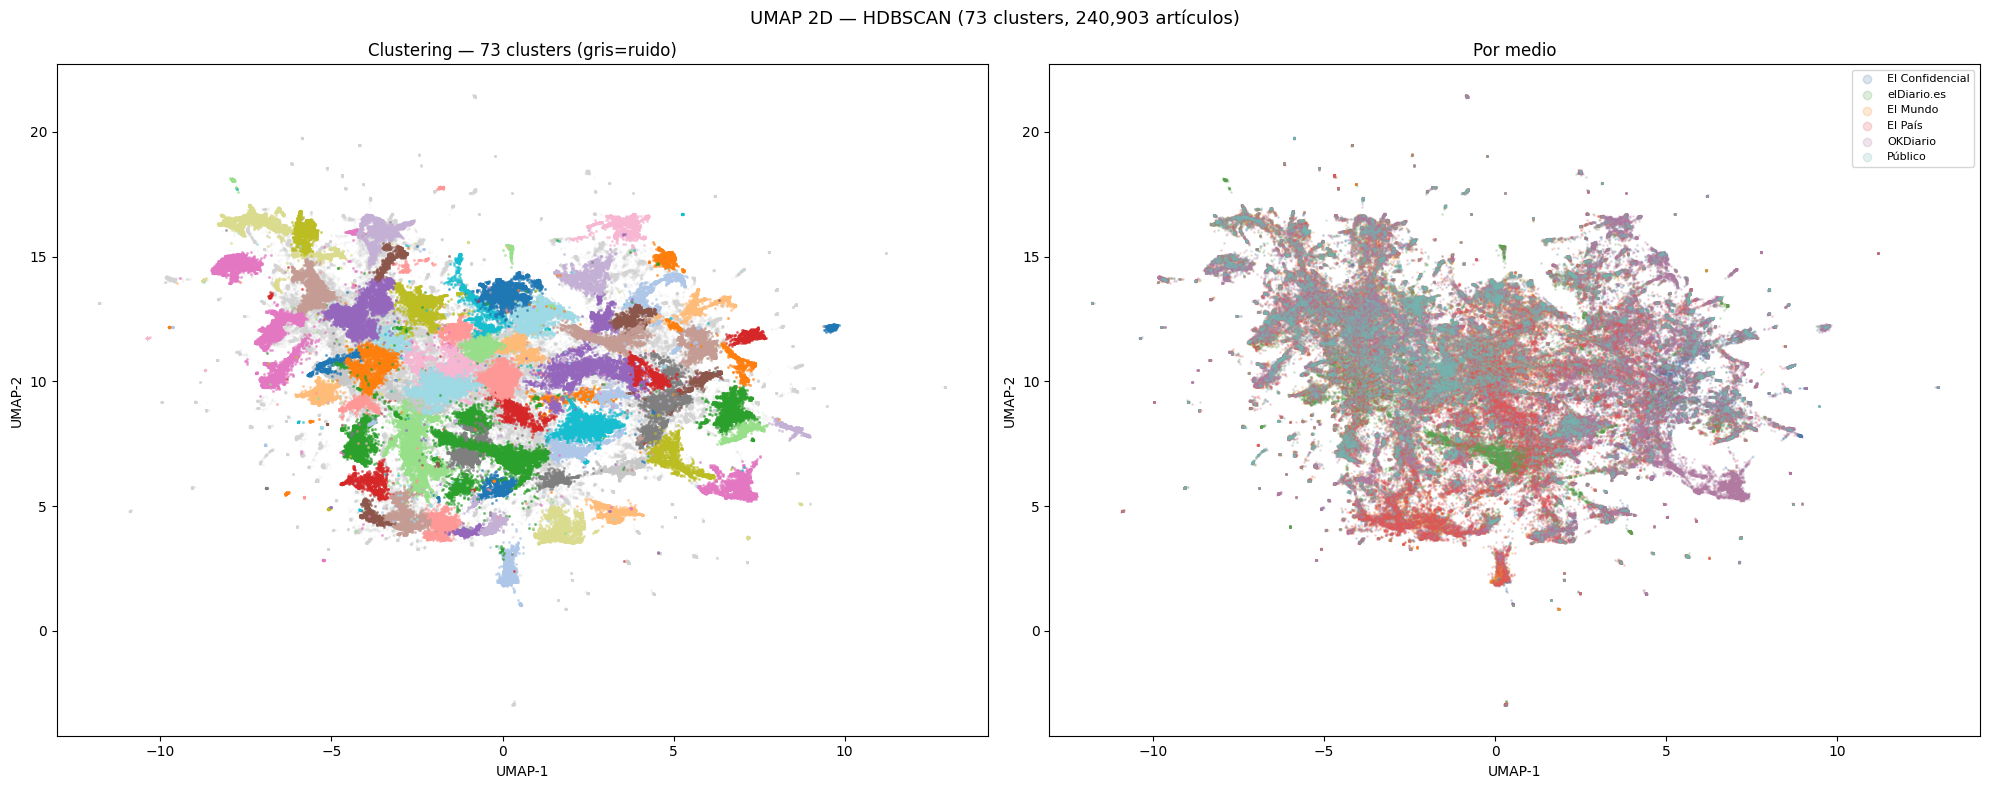

In [13]:
# Visualización clustering final
palette_c = sns.color_palette('tab20', max(n_clusters_final, 1))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

ax = axes[0]
ax.scatter(df.loc[df['cluster']==-1, 'umap_x'], df.loc[df['cluster']==-1, 'umap_y'],
           s=1, alpha=0.1, color='lightgray', rasterized=True)
for i, cid in enumerate(sorted(c for c in df['cluster'].unique() if c != -1)):
    m = df['cluster'] == cid
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1.5, alpha=0.5, color=palette_c[i % len(palette_c)],
               rasterized=True)
ax.set_title(f'Clustering — {n_clusters_final} clusters (gris=ruido)', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')

ax = axes[1]
for medio in MEDIOS:
    m = df['medio'] == medio
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1, alpha=0.2, color=COLORS[medio], label=NOMBRES[medio], rasterized=True)
ax.set_title('Por medio', fontsize=12)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(markerscale=6, fontsize=8)

alg_name = 'HDBSCAN' if usar_hdbscan else 'DBSCAN'
plt.suptitle(f'UMAP 2D — {alg_name} ({n_clusters_final} clusters, {len(df):,} artículos)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'clustering_umap.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
STOPWORDS_ES = [
    'de','la','el','en','que','y','a','los','del','se','por','con','un',
    'una','es','las','su','al','lo','para','como','más','pero','sus','le','ya',
    'o','este','sí','porque','esta','entre','cuando','muy','sin','sobre',
    'también','me','hasta','hay','donde','quien','desde','todo','nos',
    'durante','uno','ante','ellos','e','esto','mi','antes','algunos',
    'qué','unos','yo','otro','otras','otra','él','tanto','esa','estos',
    'mucho','cual','poco','ella','estar','haber','estas','estaba','fue',
    'ha','han','ser','era','si','no','son','tiene','será','así','bien',
    'parte','puede','hacer','sido','van','vez','menos','solo','cada',
    'dos','tres','según','hoy','ayer','ahora','aquí','allí','mientras',
    'aunque','después','antes','casi','aún','tan','tampoco','además',
    'ni','ya','todavía','siempre','nunca','algo','alguien',
    'te','tu','tras',
]

def top_tfidf(df_cluster, n=12):
    textos = (df_cluster['titular'].fillna('') + ' ' + df_cluster['abstract'].fillna('')).tolist()
    if len(textos) < 2:
        return []
    vec = TfidfVectorizer(
        max_features=10000, stop_words=STOPWORDS_ES,
        ngram_range=(1, 2), min_df=3
    )
    try:
        mat    = vec.fit_transform(textos)
        scores = np.asarray(mat.mean(axis=0)).ravel()
        top_i  = scores.argsort()[::-1][:n]
        return list(vec.get_feature_names_out()[top_i])
    except Exception:
        return []


print(f'=== TF-IDF por cluster ({alg_name}) ===')
resumen_clustering = []
for cid in sorted(df['cluster'].unique()):
    if cid == -1:
        continue
    df_c  = df[df['cluster'] == cid]
    kws   = top_tfidf(df_c)
    pct_m = df_c.groupby('medio').size() / len(df_c) * 100
    print(f'\nCluster {cid} | {len(df_c):6,} artículos')
    print(f'  Keywords: {" | ".join(kws[:10])}')
    print(f'  Por medio: ' + ' | '.join(f'{NOMBRES[m]}:{pct_m.get(m,0):.0f}%' for m in MEDIOS if m in pct_m.index))
    resumen_clustering.append({'cluster': cid, 'n': len(df_c), 'keywords': ', '.join(kws)})

pd.DataFrame(resumen_clustering).to_csv(OUTPUT_DIR / 'clustering_resumen.csv', index=False)

=== TF-IDF por cluster (HDBSCAN) ===

Cluster 0 |    884 artículos
  Keywords: ibex | 35 | ibex 35 | puntos | 11 | cierre | sesión | subida | puntos ibex | cierra
  Por medio: El Confidencial:2% | elDiario.es:3% | El País:1% | OKDiario:91% | Público:4%

Cluster 1 |  2,734 artículos
  Keywords: españa | lluvias | aemet | temperaturas | semana | borrasca | zonas | alerta | calor | tiempo
  Por medio: El Confidencial:42% | elDiario.es:1% | El Mundo:30% | El País:23% | OKDiario:3% | Público:0%

Cluster 2 |    807 artículos
  Keywords: barça | fútbol | continuar | leyendo | continuar leyendo | madrid | millones | club | laliga | negreira
  Por medio: El Confidencial:40% | elDiario.es:6% | El Mundo:3% | El País:14% | OKDiario:33% | Público:4%

Cluster 3 |  1,579 artículos
  Keywords: air | europa | millones | air europa | iberia | aena | vuelos | aerolínea | ryanair | aeropuerto
  Por medio: El Confidencial:26% | elDiario.es:14% | El Mundo:1% | El País:25% | OKDiario:27% | Público:7%

Cluste

### Por qué DBSCAN/HDBSCAN no son suficientes para clasificación temática

Los resultados del clustering por densidad revelan un problema estructural del dominio:

- **HDBSCAN** tiende a producir muchos micro-clusters: detecta **co-ocurrencias de eventos** (el conjunto de noticias del mismo día sobre el mismo hecho), no categorías temáticas. El espacio de embeddings de noticias tiene densidades muy altas por evento que fragmentan cualquier tema en decenas de sub-grupos.
- **DBSCAN** produce pocos clusters muy desbalanceados: agrupa por densidad geométrica global. Si hay un topic dominante (política), lo absorbe todo.

El problema es **estructural**: los temas periodísticos no forman clusters densos y separados en el espacio UMAP — se solapan porque comparten vocabulario ("gobierno", "millones", "España" aparecen en política, economía y social).

**BERTopic** resuelve esto combinando HDBSCAN con **c-TF-IDF** (término-frecuencia inversa de documento a nivel de cluster), lo que fuerza que los temas sean léxicamente distinguibles. Además permite fusionar micro-clusters de eventos en categorías temáticas más amplias.

## 6. BERTopic — modelado temático

BERTopic combina tres pasos:
1. **UMAP** (reducción dimensional interna) → 5D con `min_dist=0.0` para compactar clusters
2. **HDBSCAN** → asignación de artículos a topics latentes
3. **c-TF-IDF** → representación léxica de cada topic: mide qué palabras son características de un cluster respecto al resto del corpus

### Decisiones de diseño

| Parámetro | Valor | Justificación |
|-----------|-------|---------------|
| `min_cluster_size` | 300 | Con ~285k docs, clusters más pequeños serían micro-eventos, no temas |
| `min_samples` | 30 | Controla robustez: un punto necesita 30 vecinos para considerarse núcleo |
| `nr_topics='auto'` | — | BERTopic fusiona topics similares automáticamente por similitud coseno entre sus c-TF-IDF |
| `min_df=15` | CountVectorizer | Ignora términos muy raros (errores, nombres propios únicos); reduce ruido |
| `ngram_range=(1,2)` | — | Captura frases de 2 palabras clave como "violencia machista", "cambio climático" |

> BERTopic no reutiliza el UMAP calculado antes. Ajusta su propia reducción interna porque usa `prediction_data=True` en HDBSCAN para poder clasificar documentos nuevos.

In [15]:
BT_CACHE_PATH  = OUTPUT_DIR / 'bertopic_model.pkl'
BT_TOPICS_PATH = OUTPUT_DIR / 'bertopic_topics.npy'

textos_all   = (df['titular'].fillna('') + '. ' + df['abstract'].fillna('')).tolist()
textos_clean = [t for t, ok in zip(textos_all, mask_clean.values) if ok]

if BT_CACHE_PATH.exists() and BT_TOPICS_PATH.exists():
    print('Cargando BERTopic desde caché...')
    with open(BT_CACHE_PATH, 'rb') as fh:
        topic_model = pickle.load(fh)
    topics_full = np.load(BT_TOPICS_PATH, allow_pickle=True).tolist()
    df['topic_id'] = topics_full
    print('BERTopic cargado desde caché')
else:
    vectorizer_model = CountVectorizer(
        stop_words=STOPWORDS_ES,
        ngram_range=(1, 2),
        min_df=15,
    )

    umap_model = UMAP_bt(
        n_components=5,
        n_neighbors=20,
        min_dist=0.0,
        metric='cosine',
        random_state=42,
        low_memory=True,
    )

    hdbscan_model = HDBSCAN_bt(
        min_cluster_size=300,
        min_samples=30,
        metric='euclidean',
        cluster_selection_method='eom',
        prediction_data=True,
    )

    topic_model = BERTopic(
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        language='multilingual',
        top_n_words=20,
        calculate_probabilities=False,
        verbose=True,
    )

    print(f'Ajustando BERTopic sobre {len(textos_clean):,} artículos limpios...')
    topics_clean_list, _ = topic_model.fit_transform(textos_clean, embeddings=emb_clean)

    # Asignar topics al df completo: -1 para outliers de IsolationForest
    df['topic_id'] = -1
    df.loc[mask_clean, 'topic_id'] = topics_clean_list
    topics_full = df['topic_id'].tolist()

    with open(BT_CACHE_PATH, 'wb') as fh:
        pickle.dump(topic_model, fh)
    np.save(BT_TOPICS_PATH, np.array(topics_full, dtype=object))
    print('BERTopic listo y guardado en caché')

topic_info = topic_model.get_topic_info()
n_topics = len(topic_info) - 1
print(f'\nTopics encontrados: {n_topics} (+ outliers)')
print(topic_info[['Topic', 'Count', 'Name']].head(20).to_string(index=False))


Cargando BERTopic desde caché...
BERTopic cargado desde caché

Topics encontrados: 155 (+ outliers)
 Topic  Count                                             Name
    -1  76980                        -1_sánchez_pp_españa_psoe
     0   5850      0_migrantes_inmigrantes_inmigración_menores
     1   5337         1_vivienda_alquiler_viviendas_alquileres
     2   4372                2_dana_mazón_generalitat_valencia
     3   3536         3_amnistía_ley amnistía_puigdemont_junts
     4   3478                    4_israel_gaza_palestina_hamás
     5   3452                     5_sumar_podemos_yolanda_díaz
     6   3061              6_begoña_begoña gómez_gómez_peinado
     7   2905                  7_merlin_invento_adiós_producto
     8   2898                         8_bildu_eta_pnv_eh bildu
     9   2836                     9_hombre_detenido_mujer_años
    10   2739           10_lluvias_aemet_temperaturas_borrasca
    11   2702 11_memoria_franco_franquismo_memoria democrática
    12   2651     

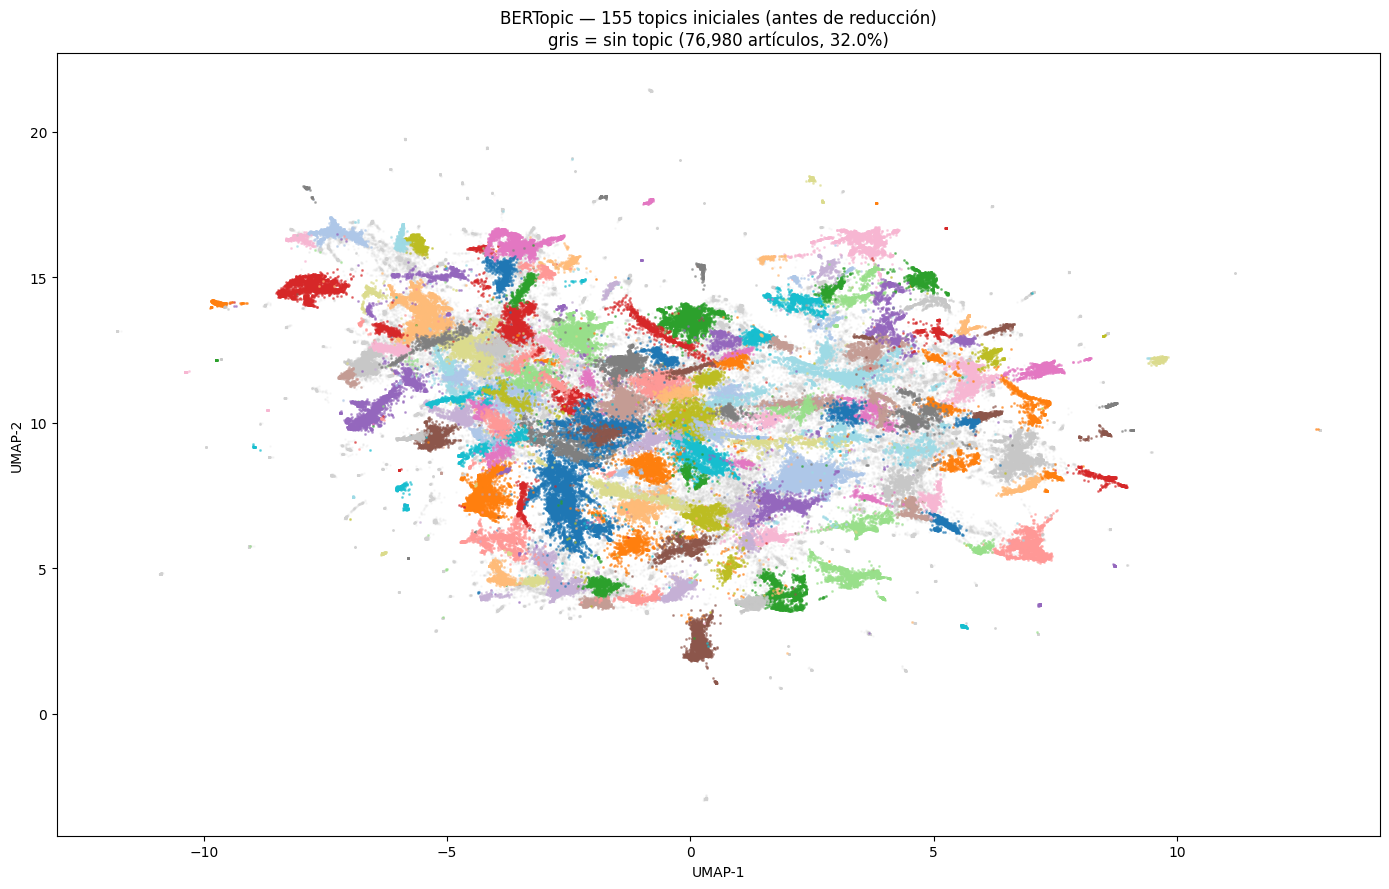

Topics iniciales: 155
Sin topic (-1)  : 76,980 (32.0%)

Top 20 topics por volumen:
 Topic  Count                                             Name
    -1  76980                        -1_sánchez_pp_españa_psoe
     0   5850      0_migrantes_inmigrantes_inmigración_menores
     1   5337         1_vivienda_alquiler_viviendas_alquileres
     2   4372                2_dana_mazón_generalitat_valencia
     3   3536         3_amnistía_ley amnistía_puigdemont_junts
     4   3478                    4_israel_gaza_palestina_hamás
     5   3452                     5_sumar_podemos_yolanda_díaz
     6   3061              6_begoña_begoña gómez_gómez_peinado
     7   2905                  7_merlin_invento_adiós_producto
     8   2898                         8_bildu_eta_pnv_eh bildu
     9   2836                     9_hombre_detenido_mujer_años
    10   2739           10_lluvias_aemet_temperaturas_borrasca
    11   2702 11_memoria_franco_franquismo_memoria democrática
    12   2651                12_kol

In [16]:
# ── UMAP coloreado por topics iniciales (antes de reducción) ──────────────
topic_info_init = topic_model.get_topic_info()
ids_init = sorted(t for t in topic_info_init['Topic'] if t != -1)
n_topics_init = len(ids_init)

palette_bt = sns.color_palette('tab20', min(n_topics_init, 20))
# Para topics > 20 repetimos paleta
color_map = {tid: palette_bt[i % 20] for i, tid in enumerate(ids_init)}
color_map[-1] = (0.82, 0.82, 0.82)  # gris para sin topic

fig, ax = plt.subplots(figsize=(14, 9))

# Primero los sin topic (gris, fondo)
m_out = df['topic_id'] == -1
ax.scatter(df.loc[m_out, 'umap_x'], df.loc[m_out, 'umap_y'],
           s=0.8, alpha=0.1, color=(0.82, 0.82, 0.82), rasterized=True,
           label=f'sin topic ({m_out.sum():,})')

# Luego cada topic
for tid in ids_init:
    m = df['topic_id'] == tid
    cnt = m.sum()
    ax.scatter(df.loc[m, 'umap_x'], df.loc[m, 'umap_y'],
               s=1.2, alpha=0.5, color=color_map[tid],
               rasterized=True)

ax.set_title(f'BERTopic — {n_topics_init} topics iniciales (antes de reducción)\n'
             f'gris = sin topic ({m_out.sum():,} artículos, {m_out.mean()*100:.1f}%)',
             fontsize=12)
ax.set_xlabel('UMAP-1')
ax.set_ylabel('UMAP-2')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bertopic_umap_inicial.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Topics iniciales: {n_topics_init}')
print(f'Sin topic (-1)  : {m_out.sum():,} ({m_out.mean()*100:.1f}%)')
print(f'\nTop 20 topics por volumen:')
print(topic_info_init[['Topic','Count','Name']].head(21).to_string(index=False))


In [17]:
N_PALABRAS  = 15
N_TITULARES = 10

topic_info = topic_model.get_topic_info()
ids_temas  = sorted(t for t in topic_info['Topic'] if t != -1)

for tid in ids_temas:
    info      = topic_info[topic_info['Topic'] == tid].iloc[0]
    words     = topic_model.get_topic(tid)
    top_words = [w for w, _ in words[:N_PALABRAS]]

    df_t    = df[df['topic_id'] == tid]
    muestra = df_t['titular'].dropna().sample(
        min(N_TITULARES, len(df_t)), random_state=42
    ).tolist()
    pct_m     = df_t.groupby('medio').size() / len(df_t) * 100
    pct_t     = df_t['tema'].fillna('sin_tema').value_counts(normalize=True) * 100
    top_temas = pct_t[pct_t >= 5].sort_values(ascending=False)

    print(f"\n{'='*72}")
    print(f"Topic {tid:3d} | {info['Count']:6,} artículos | {info['Name']}")
    print(f"  Palabras: {', '.join(top_words)}")
    print(f"  Medios:   " + ' | '.join(
        f'{NOMBRES[m]}:{pct_m.get(m,0):.0f}%' for m in MEDIOS if pct_m.get(m,0) > 1
    ))
    print(f"  Tema:     " + ' | '.join(f'{t}:{v:.0f}%' for t, v in top_temas.items()))
    print(f"  Titulares:")
    for t in muestra:
        print(f"    · {textwrap.shorten(t, width=110, placeholder='...')}")


Topic   0 |  5,850 artículos | 0_migrantes_inmigrantes_inmigración_menores
  Palabras: migrantes, inmigrantes, inmigración, menores, menores migrantes, canarias, regularización, acogida, migratoria, torre pacheco, pacheco, torre, ceuta, extranjería, reparto
  Medios:   El Confidencial:10% | elDiario.es:16% | El Mundo:15% | El País:30% | OKDiario:16% | Público:13%
  Tema:     politica:90% | economia:8%
  Titulares:
    · Torre Pacheco, el brote
    · Historia de un blanqueo: así retocó el PP la moción de Vox contra los actos islámicos en Jumilla para poder...
    · Sánchez gastará 1,4 millones en defender la inmigración como «fuente de riqueza» en plena ola de ilegales
    · Un año de la tragedia de Melilla: "Logré ocultarme bajo los migrantes. Vi gente morir"
    · PP y Vox, contra la acogida de niños migrantes y con el partido ultra culpando a Page de futuras violaciones
    · El Gobierno afirma que ya ha dado asilo en sus centros a los niños extranjeros de Canarias
    · ¿Qué es y c

### Reducción de topics

BERTopic genera inicialmente **155 topics granulares** (eventos concretos, variaciones de un mismo tema, noticias de un solo día). La reducción fusiona iterativamente los topics más similares usando similitud coseno entre sus vectores c-TF-IDF. Se solicita reducir a 30; el resultado final son **29 topics** porque BERTopic no puede fundir todos los pares sin superar el umbral mínimo de similitud coseno entre sus representaciones c-TF-IDF.


In [18]:
BT_RED_CACHE_PATH  = OUTPUT_DIR / 'bertopic_reduced_model.pkl'
BT_RED_TOPICS_PATH = OUTPUT_DIR / 'bertopic_reduced_topics.npy'

N_TEMAS_PASO1 = 30

if BT_RED_CACHE_PATH.exists() and BT_RED_TOPICS_PATH.exists():
    print('Cargando BERTopic reducido desde caché...')
    with open(BT_RED_CACHE_PATH, 'rb') as fh:
        topic_model = pickle.load(fh)
    topics_reduced = np.load(BT_RED_TOPICS_PATH, allow_pickle=True).tolist()
    df['topic_id'] = topics_reduced
    reduced_topics = [topics_reduced[i] for i, ok in enumerate(mask_clean.values) if ok]
    print('BERTopic reducido cargado desde caché')
else:
    print('Cargando modelo original (155 topics)...')
    with open(BT_CACHE_PATH, 'rb') as fh:
        topic_model = pickle.load(fh)
    n_inicial = topic_model.get_topic_info().shape[0] - 1
    print(f'Reduciendo {n_inicial} topics → {N_TEMAS_PASO1}...')
    topic_model.reduce_topics(textos_clean, nr_topics=N_TEMAS_PASO1)
    reduced_topics = topic_model.topics_
    df['topic_id'] = -1
    df.loc[mask_clean, 'topic_id'] = reduced_topics
    with open(BT_RED_CACHE_PATH, 'wb') as fh:
        pickle.dump(topic_model, fh)
    np.save(BT_RED_TOPICS_PATH, np.array(df['topic_id'].tolist(), dtype=object))
    print('Reducción completada y guardada en caché')

topic_info_red = topic_model.get_topic_info()
ids_red = sorted(t for t in topic_info_red['Topic'] if t != -1)
n_sin = (df['topic_id'] == -1).sum()

print(f'\nTopics tras reducción a {N_TEMAS_PASO1}: {len(ids_red)}')
print(f'Sin topic (-1): {n_sin:,} ({n_sin/len(df)*100:.1f}%)')
print()
for tid in ids_red:
    row   = topic_info_red[topic_info_red['Topic'] == tid].iloc[0]
    words = [w for w, _ in topic_model.get_topic(tid)[:12]]
    print(f'  Topic {tid:3d} | {row["Count"]:6,} arts | {", ".join(words)}')


Cargando BERTopic reducido desde caché...
BERTopic reducido cargado desde caché

Topics tras reducción a 30: 29
Sin topic (-1): 76,980 (32.0%)

  Topic   0 | 49,485 arts | pp, sánchez, vox, gobierno, psoe, feijóo, amnistía, partido, presidente, elecciones, contra, dana
  Topic   1 | 17,037 arts | begoña, juez, gómez, begoña gómez, koldo, caso, ábalos, fiscal, supremo, garcía, sánchez, fiscal general
  Topic   2 |  9,658 arts | pensiones, seguridad social, social, pensión, jubilación, seguridad, laboral, jornada, españa, mínimo, empleo, paro
  Topic   3 |  7,574 arts | vivienda, alquiler, viviendas, pisos, precio, alquileres, precios, casas, 000, ley, españa, turísticos
  Topic   4 |  7,080 arts | hombre, incendio, años, incendios, detenido, mujer, muere, fuego, policía, joven, menor, heridos
  Topic   5 |  5,695 arts | millones, telefónica, indra, compañía, millones euros, euros, coches, empresa, grupo, bolsa, compra, españa
  Topic   6 |  5,165 arts | trump, mundo, política, democraci

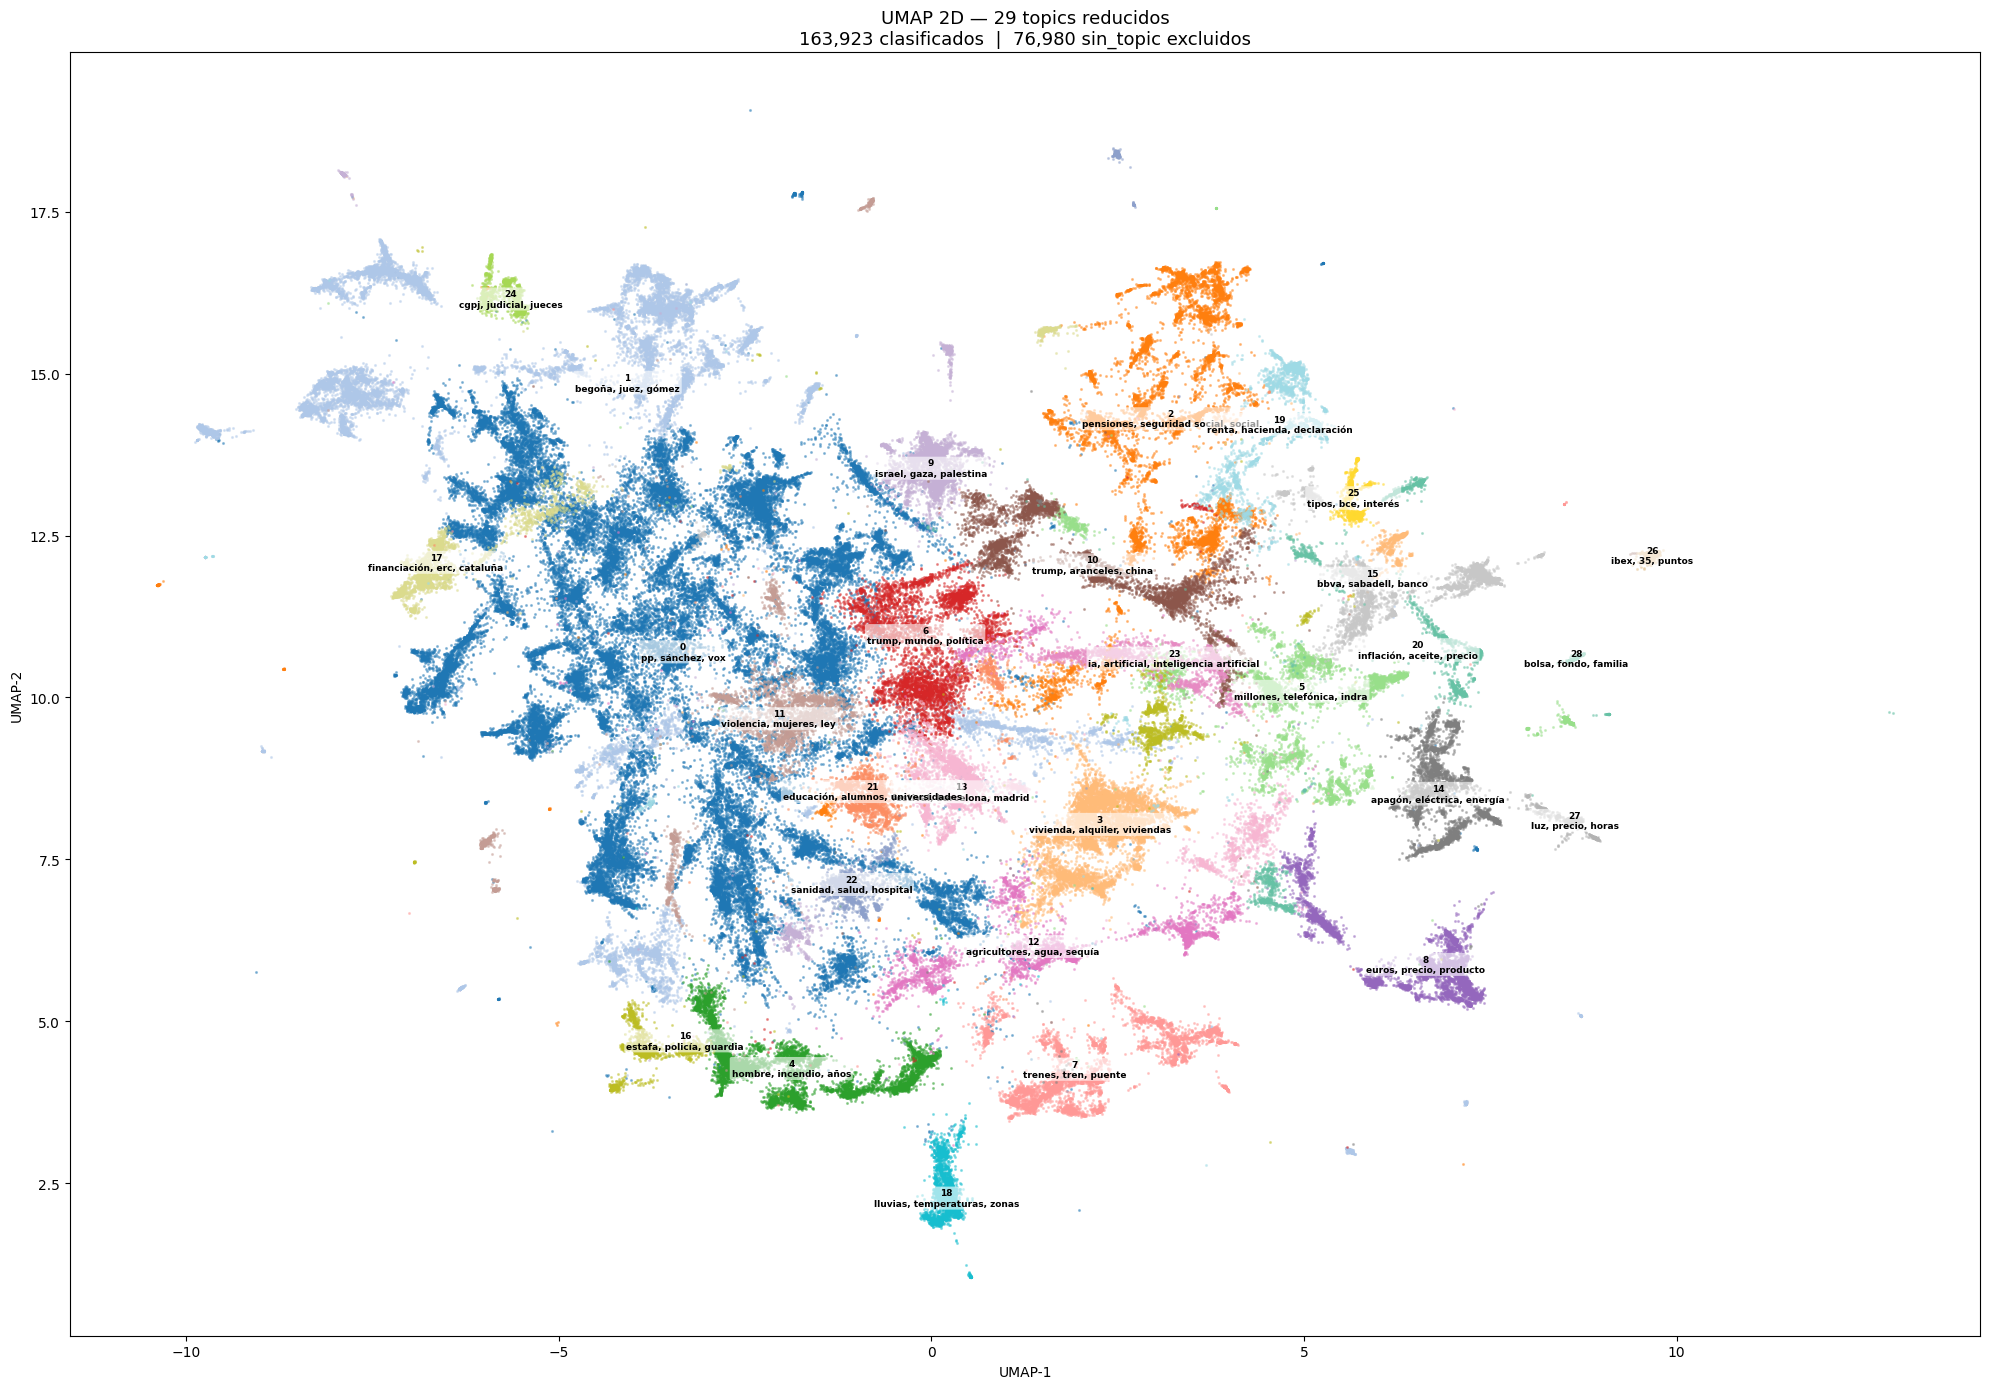

In [19]:
# ── UMAP 2D con números de topic sobre cada cluster ─────────────────────
# Usa el UMAP 2D externo (umap_x, umap_y) — el mismo de todas las visualizaciones

df_ok  = df[df['topic_id'] != -1].dropna(subset=['umap_x'])
ids_ok = sorted(df_ok['topic_id'].unique())
pal    = sns.color_palette('tab20', 20) + sns.color_palette('Set2', 10)
cmap   = {tid: pal[i % 30] for i, tid in enumerate(ids_ok)}

fig, ax = plt.subplots(figsize=(20, 14))

for tid in ids_ok:
    m = df_ok['topic_id'] == tid
    ax.scatter(df_ok.loc[m, 'umap_x'], df_ok.loc[m, 'umap_y'],
               s=1.5, alpha=0.4, color=cmap[tid], rasterized=True)

# Número + top 3 palabras sobre el centroide de cada cluster
for tid in ids_ok:
    m  = df_ok['topic_id'] == tid
    cx = df_ok.loc[m, 'umap_x'].median()
    cy = df_ok.loc[m, 'umap_y'].median()
    words = [w for w, _ in topic_model.get_topic(tid)[:3]]
    label = f"{tid}\n{', '.join(words)}"
    ax.text(cx, cy, label, fontsize=6.5, ha='center', va='center',
            fontweight='bold', color='black',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6, lw=0))

n_sin = (df['topic_id'] == -1).sum()
ax.set_title(f'UMAP 2D — {len(ids_ok)} topics reducidos\n'
             f'{len(df_ok):,} clasificados  |  {n_sin:,} sin_topic excluidos', fontsize=13)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bertopic_umap_29topics.png', dpi=150, bbox_inches='tight')
plt.show()


### 6.3 Reducción de outliers — `reduce_outliers`

Tras la reducción a 29 topics, el **32 % de los artículos** (76 980) quedan con `topic_id == -1`.
BERTopic los trata como ruido porque no superan `min_cluster_size` o caen en zonas de baja densidad.
Con `reduce_outliers` se les asigna el topic más cercano usando c-TF-IDF.

| Parámetro | Valor | Justificación |
|-----------|-------|---------------|
| `strategy` | `"c-tf-idf"` | Asigna cada outlier al topic cuya representación c-TF-IDF es más similar a su TF-IDF individual. Rápido y eficaz para texto. |
| `threshold` | `0.0` | Sin umbral mínimo de similitud → todos los outliers reciben un topic. |

> **`update_topics`** recalcula las representaciones c-TF-IDF de los 29 topics incluyendo
> los documentos que antes eran outliers — necesario para que el etiquetado manual
> de la sección 7 refleje el corpus completo.

In [24]:
BT_NOOUT_PATH = OUTPUT_DIR / 'bertopic_nooutlier_topics.npy'

if BT_NOOUT_PATH.exists():
    print('Cargando topics sin outliers desde caché...')
    topics_noout = np.load(BT_NOOUT_PATH, allow_pickle=True).tolist()
    df['topic_id'] = topics_noout
    print('Cargado desde caché')
else:
    topics_before = df['topic_id'].tolist()
    n_out_antes   = sum(1 for t in topics_before if t == -1)
    print(f'Outliers antes  : {n_out_antes:,} ({n_out_antes / len(topics_before) * 100:.1f}%)')

    print('Aplicando reduce_outliers (strategy=c-tf-idf)...')
    # En BERTopic 0.17.x reduce_outliers devuelve List[int], no tupla
    topics_noout = topic_model.reduce_outliers(
        textos_clean,
        topics_before,
        strategy='c-tf-idf',
        threshold=0.0,
    )

    # Recalcular representaciones c-TF-IDF incluyendo los ex-outliers
    topic_model.update_topics(textos_clean, topics=topics_noout)

    df['topic_id'] = topics_noout
    np.save(BT_NOOUT_PATH, np.array(topics_noout, dtype=object))
    print('Guardado en caché → bertopic_nooutlier_topics.npy')

n_out_despues  = sum(1 for t in df['topic_id'] if t == -1)
n_clasificados = len(df) - n_out_despues
print(f'\nOutliers después : {n_out_despues:,} ({n_out_despues / len(df) * 100:.1f}%)')
print(f'Clasificados     : {n_clasificados:,} ({n_clasificados / len(df) * 100:.1f}%)')

print('\n=== Artículos por topic tras reduce_outliers ===')
ti = topic_model.get_topic_info()
print(ti[ti['Topic'] != -1][['Topic', 'Count']].sort_values('Topic').to_string(index=False))


Outliers antes  : 76,980 (32.0%)
Aplicando reduce_outliers (strategy=c-tf-idf)...


2026-05-08 00:28:38,155 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Guardado en caché → bertopic_nooutlier_topics.npy

Outliers después : 21 (0.0%)
Clasificados     : 240,882 (100.0%)

=== Artículos por topic tras reduce_outliers ===
 Topic  Count
     0  65390
     1  22288
     2  13311
     3   9181
     4  10100
     5  10889
     6  12253
     7   6643
     8   6701
     9   5957
    10   7603
    11   7113
    12   5745
    13   7294
    14   4836
    15   4675
    16   5791
    17   5381
    18   3331
    19   3580
    20   3257
    21   3638
    22   3579
    23   2470
    24   3166
    25   1615
    26   1285
    27   1416
    28   2394


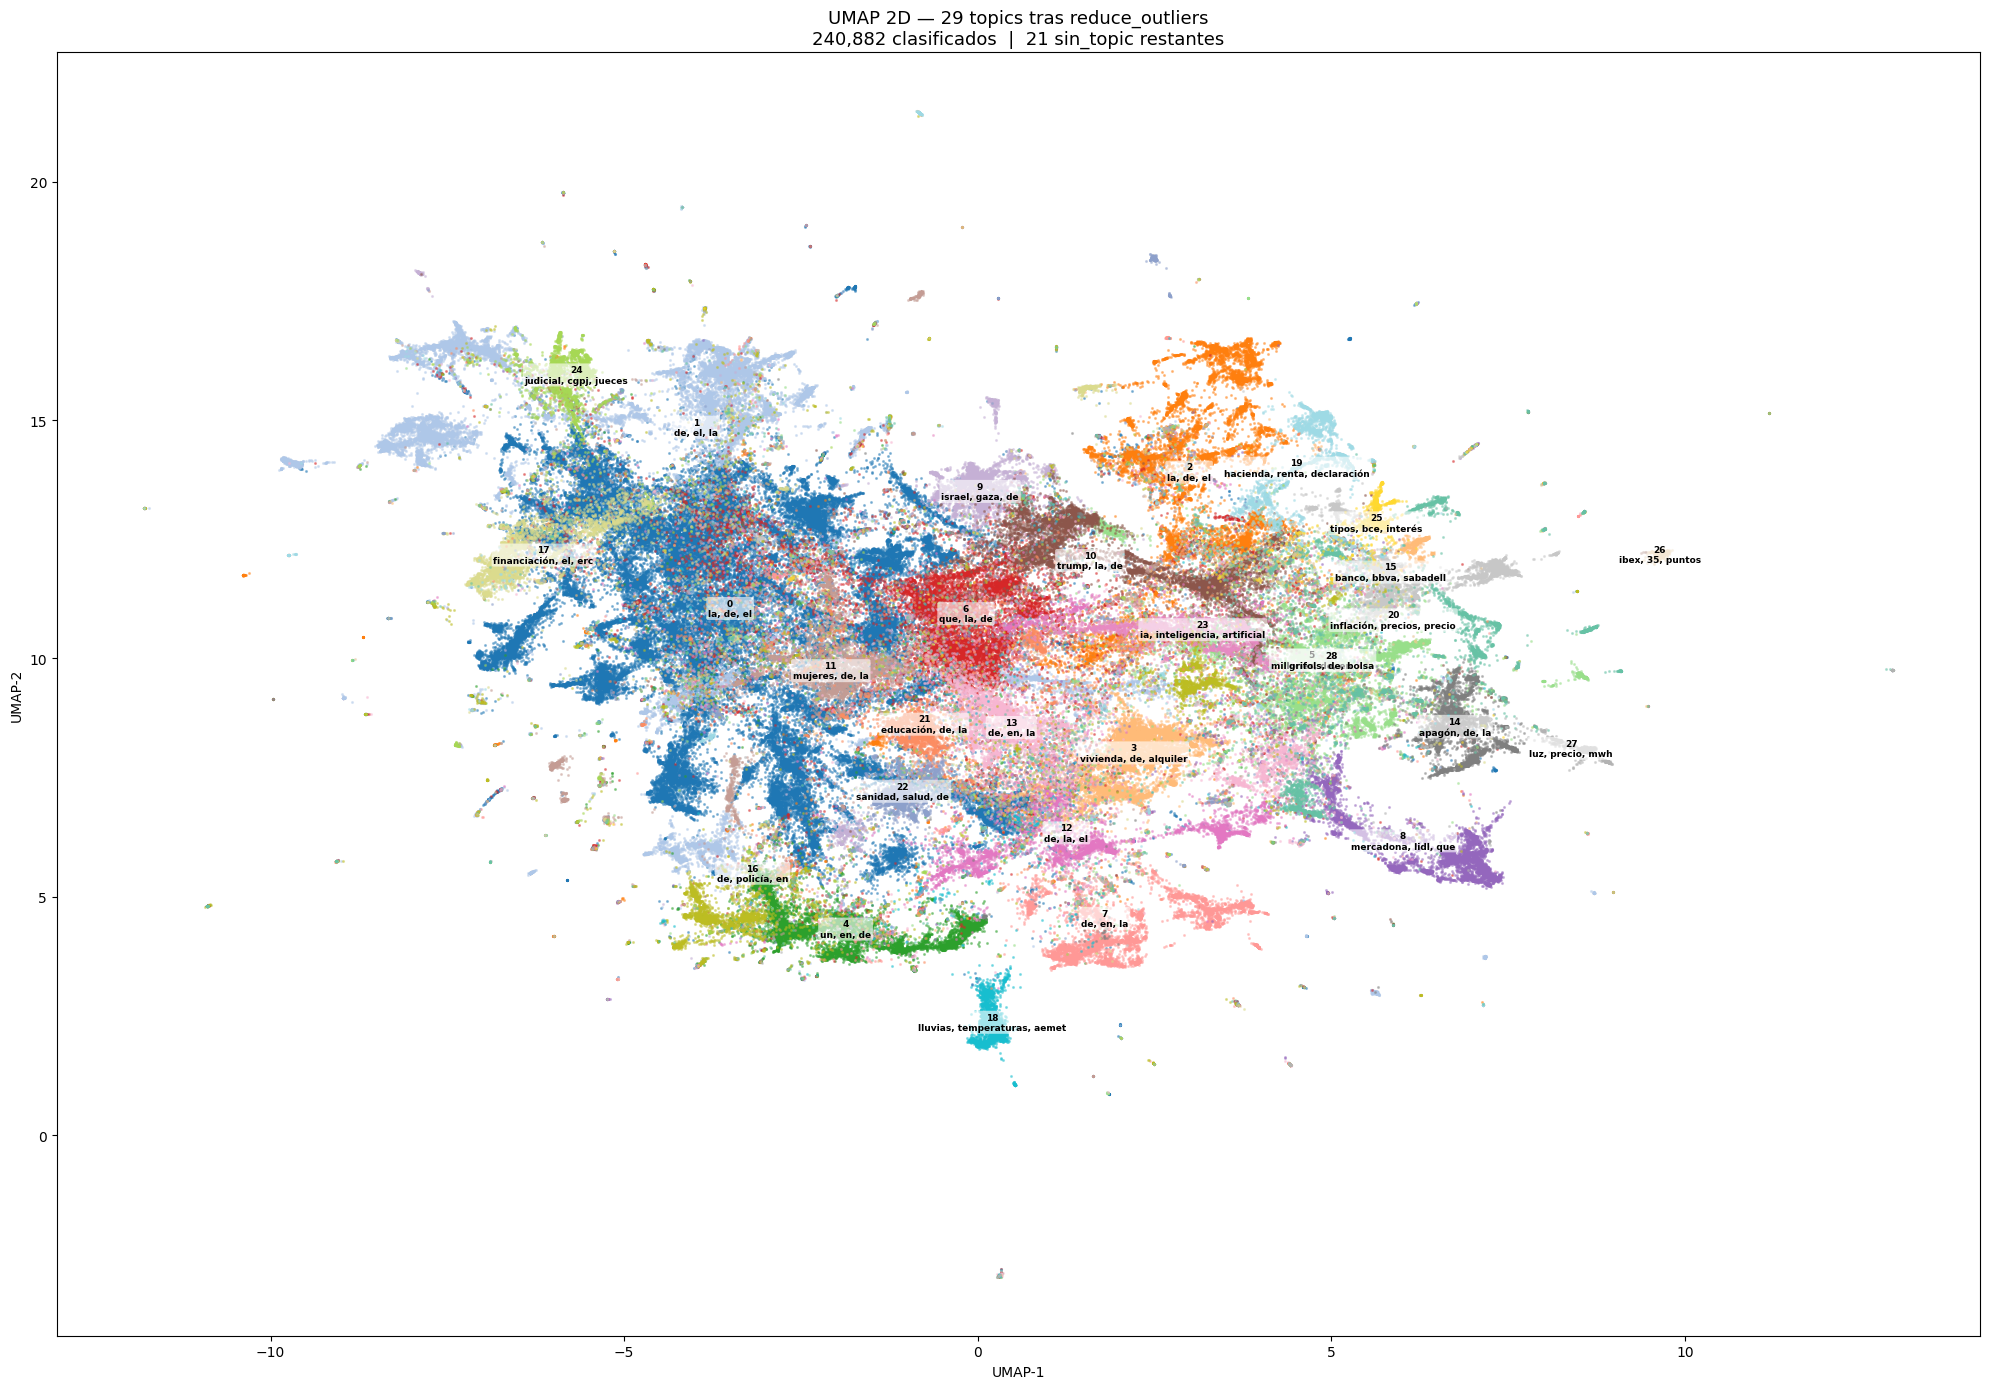

In [25]:
# ── UMAP 2D tras reduce_outliers (todos los artículos clasificados) ────────
df_ok2  = df[df['topic_id'] != -1].dropna(subset=['umap_x'])
ids_ok2 = sorted(df_ok2['topic_id'].unique())
pal     = sns.color_palette('tab20', 20) + sns.color_palette('Set2', 10)
cmap2   = {tid: pal[i % 30] for i, tid in enumerate(ids_ok2)}

fig, ax = plt.subplots(figsize=(20, 14))

for tid in ids_ok2:
    m = df_ok2['topic_id'] == tid
    ax.scatter(df_ok2.loc[m, 'umap_x'], df_ok2.loc[m, 'umap_y'],
               s=1.5, alpha=0.4, color=cmap2[tid], rasterized=True)

# Número + top 3 palabras sobre el centroide de cada cluster
for tid in ids_ok2:
    m  = df_ok2['topic_id'] == tid
    cx = df_ok2.loc[m, 'umap_x'].median()
    cy = df_ok2.loc[m, 'umap_y'].median()
    words = [w for w, _ in topic_model.get_topic(tid)[:3]]
    label = f"{tid}\n{', '.join(words)}"
    ax.text(cx, cy, label, fontsize=6.5, ha='center', va='center',
            fontweight='bold', color='black',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.6, lw=0))

n_sin2 = (df['topic_id'] == -1).sum()
ax.set_title(
    f'UMAP 2D — {len(ids_ok2)} topics tras reduce_outliers\n'
    f'{len(df_ok2):,} clasificados  |  {n_sin2:,} sin_topic restantes',
    fontsize=13
)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bertopic_umap_nooutliers.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Etiquetado manual de topics

El etiquetado se basa en las top-20 palabras c-TF-IDF y en la inspección de titulares representativos. No es automático.

In [26]:
# ── Etiquetado manual de los 29 topics BERTopic reducidos y creación de macrotemas ──────────────────
CLUSTER_LABELS = {
    0:  {"nombre": "politica_partidos",          "macrotema": "politica_nacional"},
    1:  {"nombre": "corrupcion_judicial",         "macrotema": "justicia_corrupcion"},
    2:  {"nombre": "empleo_pensiones",            "macrotema": "economia_social"},
    3:  {"nombre": "vivienda_alquiler",           "macrotema": "economia_social"},
    4:  {"nombre": "sucesos_incendios",           "macrotema": "sucesos_seguridad"},
    5:  {"nombre": "empresas_mercados",           "macrotema": "macroeconomia"},
    6:  {"nombre": "opinion_internacional",       "macrotema": "internacional"},
    7:  {"nombre": "transporte_infraestructuras", "macrotema": "sucesos_seguridad"},
    8:  {"nombre": "consumo_precios",             "macrotema": "economia_social"},
    9:  {"nombre": "conflictos_oriente",          "macrotema": "internacional"},
    10: {"nombre": "geopolitica_eeuu",            "macrotema": "internacional"},
    11: {"nombre": "violencia_genero",            "macrotema": "derechos_sociales"},
    12: {"nombre": "agricultura_medioambiente",   "macrotema": "sucesos_seguridad"},
    13: {"nombre": "cultura_ocio",                "macrotema": "derechos_sociales"},
    14: {"nombre": "energia_electrica",           "macrotema": "sucesos_seguridad"},
    15: {"nombre": "banca_finanzas",              "macrotema": "macroeconomia"},
    16: {"nombre": "seguridad_policial",          "macrotema": "sucesos_seguridad"},
    17: {"nombre": "politica_autonomica",         "macrotema": "politica_nacional"},
    18: {"nombre": "meteorologia",                "macrotema": "sucesos_seguridad"},
    19: {"nombre": "fiscalidad_hacienda",         "macrotema": "economia_social"},
    20: {"nombre": "inflacion_precios",           "macrotema": "economia_social"},
    21: {"nombre": "educacion",                   "macrotema": "derechos_sociales"},
    22: {"nombre": "sanidad",                     "macrotema": "derechos_sociales"},
    23: {"nombre": "tecnologia_ia",               "macrotema": "tecnologia"},
    24: {"nombre": "poder_judicial",              "macrotema": "justicia_corrupcion"},
    25: {"nombre": "politica_monetaria",          "macrotema": "macroeconomia"},
    26: {"nombre": "bolsa_ibex",                  "macrotema": "macroeconomia"},
    27: {"nombre": "precio_luz",                  "macrotema": "sucesos_seguridad"},
    28: {"nombre": "fondos_inversion",            "macrotema": "macroeconomia"},
}

MACROTEMAS_ORDEN = [
    'politica_nacional', 'justicia_corrupcion', 'economia_social',
    'macroeconomia', 'sucesos_seguridad', 'internacional',
    'derechos_sociales', 'tecnologia',
]

# Mapeo al DataFrame
df['nombre']    = df['topic_id'].map(lambda t: CLUSTER_LABELS[t]['nombre']    if t in CLUSTER_LABELS else 'sin_clasificar')
df['macrotema'] = df['topic_id'].map(lambda t: CLUSTER_LABELS[t]['macrotema'] if t in CLUSTER_LABELS else 'sin_clasificar')
df['tematica']  = df['nombre']   # alias para sección 9

temas_clasificados = list(CLUSTER_LABELS.keys())

# Tabla resumen
resumen_labels = pd.DataFrame([
    {'topic_id': t,
     'nombre':   v['nombre'],
     'macrotema': v['macrotema'],
     'n_articulos': int((df['topic_id'] == t).sum())}
    for t, v in sorted(CLUSTER_LABELS.items())
])
print('Etiquetas asignadas de los 29 cluster a macrotemas')
print(resumen_labels.to_string(index=False))
print(f'\nTotal artículos clasificados : {(df["topic_id"].isin(CLUSTER_LABELS)).sum():,}')
print(f'Sin clasificar (-1)          : {(df["topic_id"] == -1).sum():,}')


Etiquetas asignadas de los 29 cluster a macrotemas
 topic_id                      nombre           macrotema  n_articulos
        0           politica_partidos   politica_nacional        65390
        1         corrupcion_judicial justicia_corrupcion        22288
        2            empleo_pensiones     economia_social        13311
        3           vivienda_alquiler     economia_social         9181
        4           sucesos_incendios   sucesos_seguridad        10100
        5           empresas_mercados       macroeconomia        10889
        6       opinion_internacional       internacional        12253
        7 transporte_infraestructuras   sucesos_seguridad         6643
        8             consumo_precios     economia_social         6701
        9          conflictos_oriente       internacional         5957
       10            geopolitica_eeuu       internacional         7603
       11            violencia_genero   derechos_sociales         7113
       12   agricultura_me

In [27]:
# ── Guardar etiquetas como JSON ────────────────────────────────────────────
labels_out = {
    str(k): {"nombre": v["nombre"], "macrotema": v["macrotema"]}
    for k, v in sorted(CLUSTER_LABELS.items())
}
(OUTPUT_DIR / 'cluster_labels.json').write_text(
    json.dumps(labels_out, ensure_ascii=False, indent=2), encoding='utf-8'
)
print(f'Labels guardados → {OUTPUT_DIR / "cluster_labels.json"}')

# ── Distribución por macrotema ─────────────────────────────────────────────
print(f'\n8 macrotemas: {MACROTEMAS_ORDEN}')
tabla_macro = (
    df[df['macrotema'] != 'sin_clasificar']
    .groupby('macrotema').size()
    .reindex(MACROTEMAS_ORDEN)
    .rename('artículos')
)
print('\n=== Artículos por macrotema ===')
print(tabla_macro.to_string())
print(f'\nTotal clasificados: {tabla_macro.sum():,} | Sin clasificar: {(df["macrotema"]=="sin_clasificar").sum():,}')


Labels guardados → ../output/clustering_6medios/cluster_labels.json

8 macrotemas: ['politica_nacional', 'justicia_corrupcion', 'economia_social', 'macroeconomia', 'sucesos_seguridad', 'internacional', 'derechos_sociales', 'tecnologia']

=== Artículos por macrotema ===
macrotema
politica_nacional      70771
justicia_corrupcion    25454
economia_social        36030
macroeconomia          20858
sucesos_seguridad      37862
internacional          25813
derechos_sociales      21624
tecnologia              2470

Total clasificados: 240,882 | Sin clasificar: 21


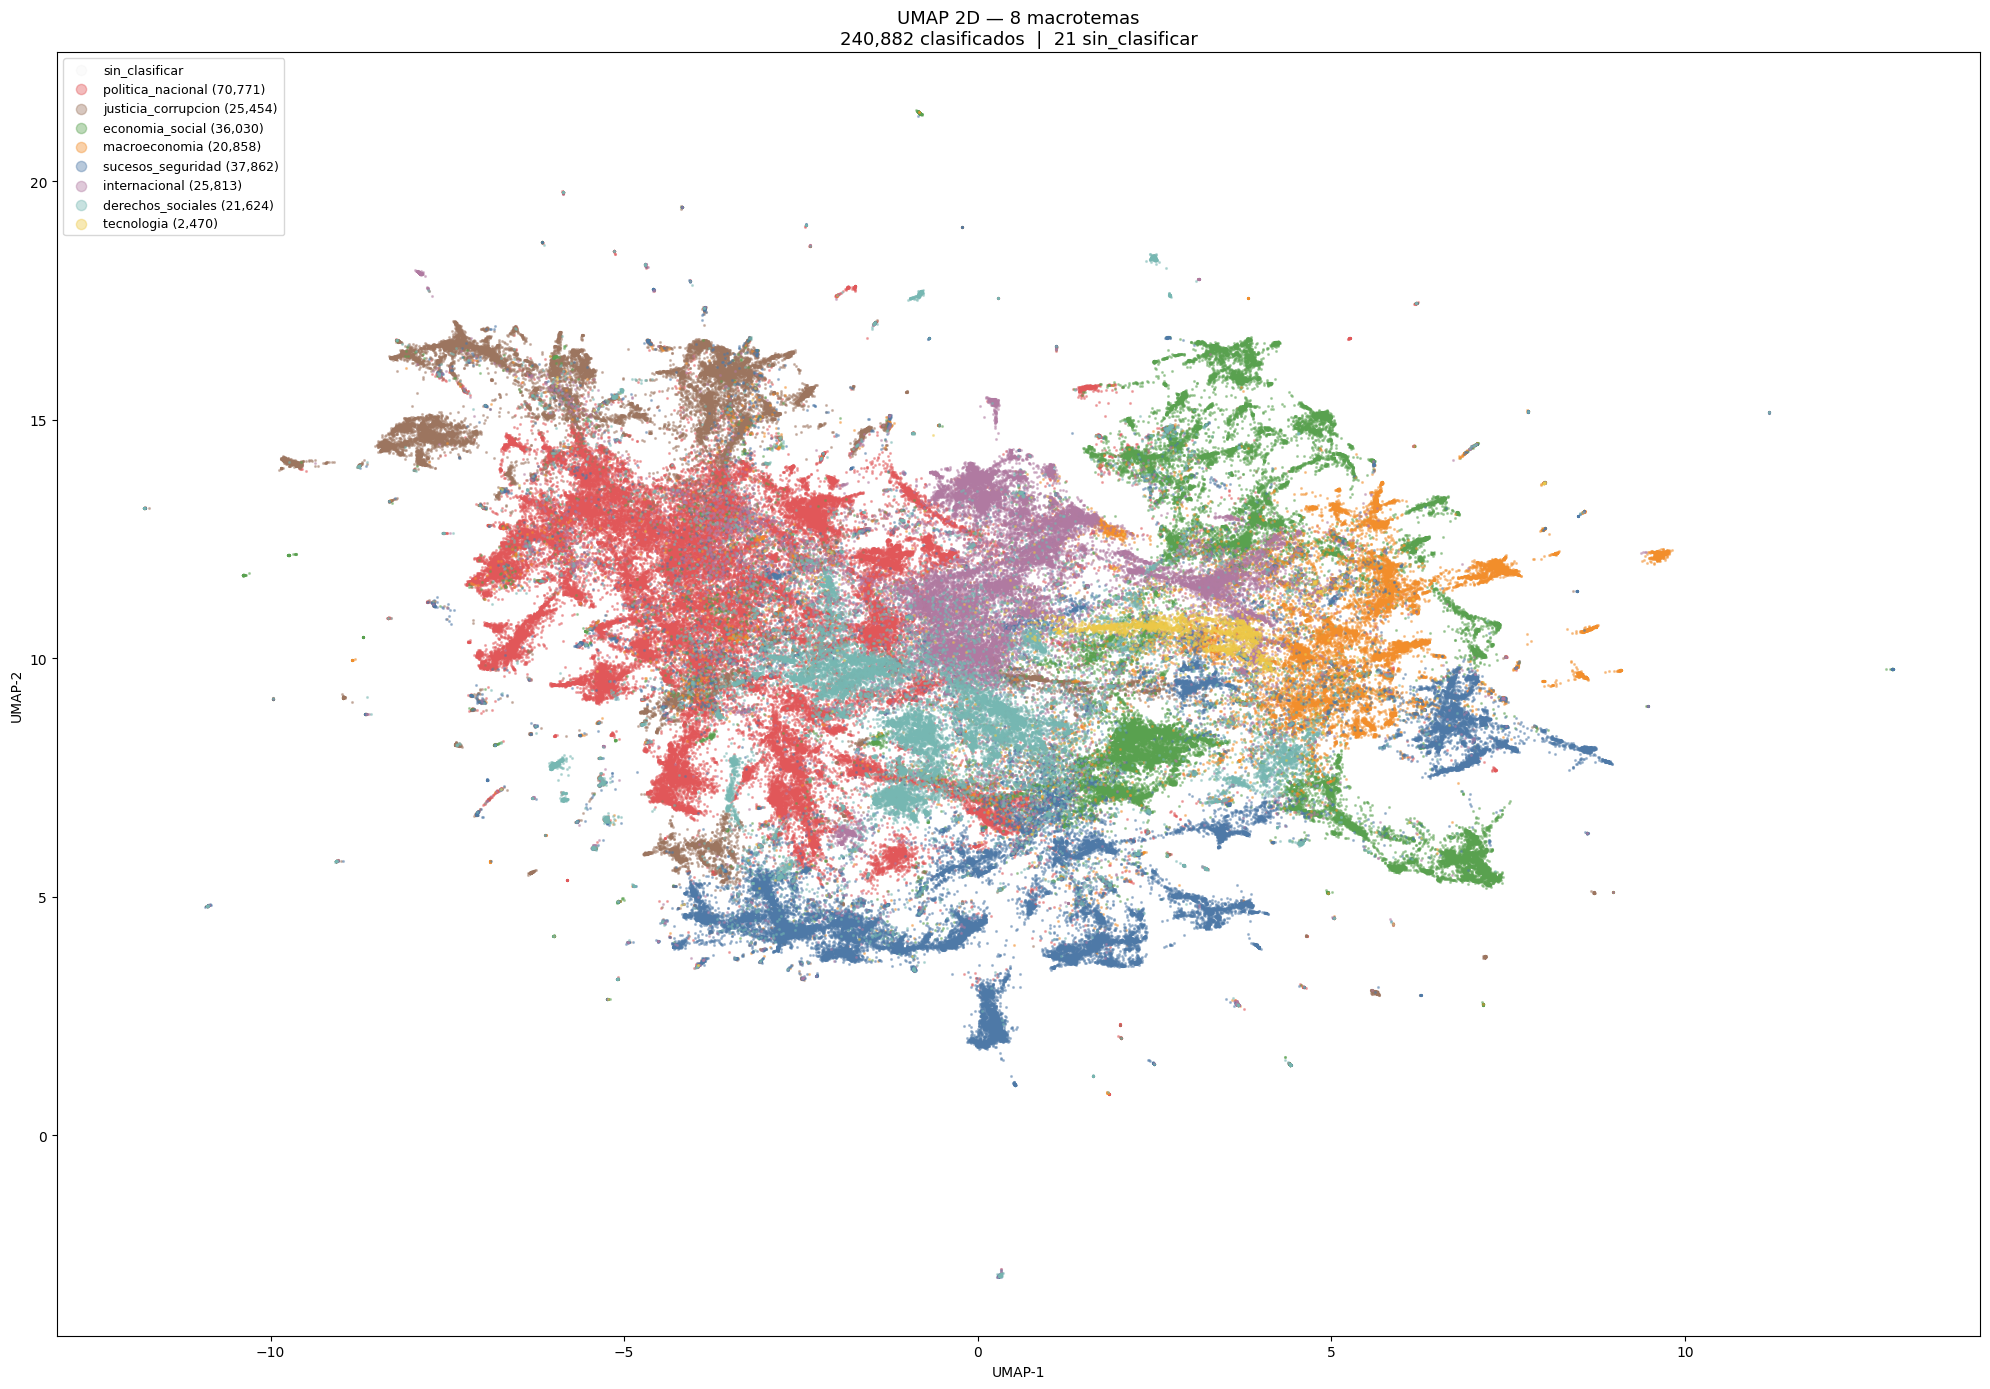

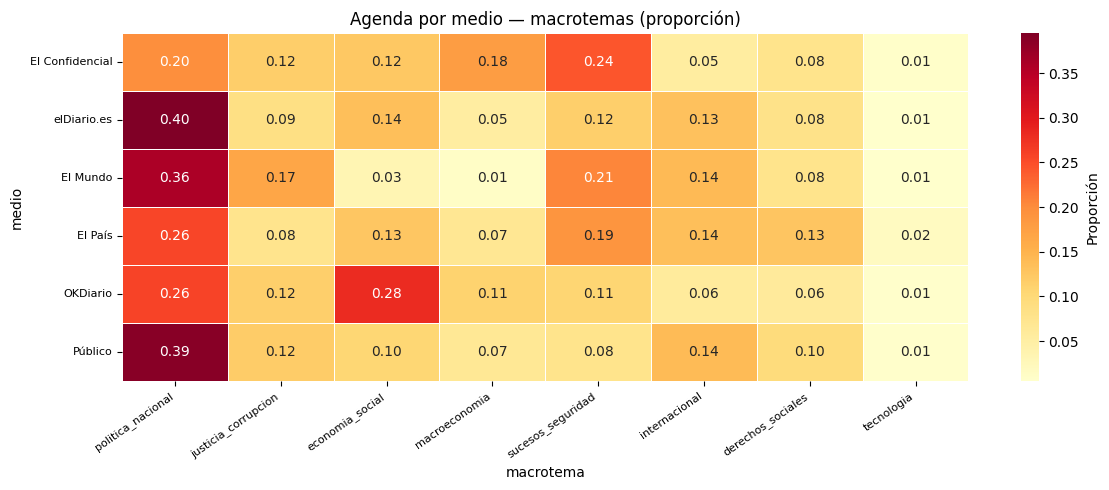

Figuras guardadas → bertopic_umap_macrotemas.png, bertopic_heatmap.png


In [31]:
# ── UMAP coloreado por macrotema ─────────────────────────────────────────
MACROTEMA_COLORS = {
    'politica_nacional':   '#e15759',
    'justicia_corrupcion': '#9c755f',
    'economia_social':     '#59a14f',
    'macroeconomia':       '#f28e2b',
    'sucesos_seguridad':   '#4e79a7',
    'internacional':       '#b07aa1',
    'derechos_sociales':   '#76b7b2',
    'tecnologia':          '#edc948',
}

df_mac = df[df['macrotema'] != 'sin_clasificar'].dropna(subset=['umap_x'])

fig, ax = plt.subplots(figsize=(20, 14))

# Puntos sin clasificar (gris, fondo)
m_noise = df['macrotema'] == 'sin_clasificar'
ax.scatter(df.loc[m_noise, 'umap_x'], df.loc[m_noise, 'umap_y'],
           s=1.5, alpha=0.08, color='lightgray', rasterized=True, label='sin_clasificar')

# Un color por macrotema — label para la leyenda
for mac in MACROTEMAS_ORDEN:
    m = df_mac['macrotema'] == mac
    n = m.sum()
    ax.scatter(df_mac.loc[m, 'umap_x'], df_mac.loc[m, 'umap_y'],
               s=1.5, alpha=0.4, color=MACROTEMA_COLORS[mac],
               rasterized=True, label=f'{mac} ({n:,})')

n_sin = m_noise.sum()
ax.set_title(
    f'UMAP 2D — 8 macrotemas\n'
    f'{len(df_mac):,} clasificados  |  {n_sin:,} sin_clasificar',
    fontsize=13
)
ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
ax.legend(markerscale=6, fontsize=9, loc='upper left',
          framealpha=0.9, edgecolor='lightgray')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bertopic_umap_macrotemas.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Heatmap agenda por medio ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
tabla_medio_macro = pd.crosstab(df_mac['medio'], df_mac['macrotema'], normalize='index').round(3)
tabla_medio_macro = tabla_medio_macro.reindex(columns=MACROTEMAS_ORDEN, fill_value=0)
sns.heatmap(
    tabla_medio_macro, annot=True, fmt='.2f',
    cmap='YlOrRd', linewidths=0.5, ax=ax,
    cbar_kws={'label': 'Proporción'},
)
ax.set_title('Agenda por medio — macrotemas (proporción)', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right', fontsize=8)
ax.set_yticklabels([NOMBRES[m] for m in tabla_medio_macro.index], rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'bertopic_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figuras guardadas → bertopic_umap_macrotemas.png, bertopic_heatmap.png')


## 8. Resumen y conclusiones

### Pipeline ejecutado
1. **Carga**: 241k artículos de 6 medios con embeddings de 1024 dimensiones.
2. **UMAP 5D**: reducción dimensional para clustering (cosine, n_neighbors=30, min_dist=0).
3. **Optuna (HDBSCAN + DBSCAN)**: búsqueda de hiperparámetros óptimos por silhouette score.
4. **BERTopic**: modelado temático con c-TF-IDF, reducido a 29 topics + reasignación de outliers con `reduce_outliers`.
5. **Etiquetado**: asignación manual de etiqueta temática y macrotema a cada topic → `cluster_labels.json`.
6. **Cobertura**: columna `tematica` y `macrotema` añadidas al DataFrame para todos los artículos.

### Limitaciones

In [33]:
# ── Resumen final ──────────────────────────────────────────────────────────
n_clasificados = (df['tematica'] != 'sin_clasificar').sum()
n_sin          = (df['tematica'] == 'sin_clasificar').sum()
n_exout        = int(df['era_outlier'].sum()) if 'era_outlier' in df.columns else 'n/a'

print('=' * 60)
print('RESUMEN FINAL')
print('=' * 60)

print(f'\n── Corpus ──────────────────────────────')
print(f'Total artículos            : {len(df):,}')
print(f'Medios                     : {len(MEDIOS)}')
for medio in MEDIOS:
    n = (df['medio'] == medio).sum()
    print(f'  {NOMBRES[medio]:<22} {n:>7,}')

print(f'\n── Pipeline BERTopic ───────────────────')
print(f'Topics iniciales           : 155')
print(f'Topics tras reduce_topics  : {len(temas_clasificados)}')
print(f'Ex-outliers reasignados    : {n_exout:,}' if isinstance(n_exout, int) else f'Ex-outliers reasignados    : {n_exout}')

print(f'\n── Etiquetado manual ───────────────────')
print(f'Topics etiquetados         : {len(CLUSTER_LABELS)}')
print(f'Macrotemas                 : {len(MACROTEMAS_ORDEN)}')
for mac in MACROTEMAS_ORDEN:
    n_mac = (df['macrotema'] == mac).sum()
    print(f'  {mac:<30} {n_mac:>7,}')

print(f'\n── Cobertura ───────────────────────────')
print(f'Artículos clasificados     : {n_clasificados:,} ({n_clasificados/len(df)*100:.1f}%)')
print(f'Artículos sin clasificar   : {n_sin:,} ({n_sin/len(df)*100:.1f}%)')

print(f'\n── Outputs ─────────────────────────────')
print(f'{OUTPUT_DIR.resolve()}')
for f in sorted(OUTPUT_DIR.glob('*.png')) :
    print(f'  {f.name}')
for f in sorted(OUTPUT_DIR.glob('*.json')):
    print(f'  {f.name}')


RESUMEN FINAL

── Corpus ──────────────────────────────
Total artículos            : 240,903
Medios                     : 6
  El Confidencial         36,483
  elDiario.es             38,463
  El Mundo                22,994
  El País                 64,933
  OKDiario                51,973
  Público                 26,057

── Pipeline BERTopic ───────────────────
Topics iniciales           : 155
Topics tras reduce_topics  : 29
Ex-outliers reasignados    : n/a

── Etiquetado manual ───────────────────
Topics etiquetados         : 29
Macrotemas                 : 8
  politica_nacional               70,771
  justicia_corrupcion             25,454
  economia_social                 36,030
  macroeconomia                   20,858
  sucesos_seguridad               37,862
  internacional                   25,813
  derechos_sociales               21,624
  tecnologia                       2,470

── Cobertura ───────────────────────────
Artículos clasificados     : 240,882 (100.0%)
Artículos sin cla